### Visualize full data dimensionality reduction

In [1]:
import scanpy as sc
from collections import Counter
import numpy as np
import pandas as pd
import scipy.sparse
import anndata
import os
import time
import sys
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from typing import Union
from IPython.display import Image, display, Markdown, IFrame
import re
from wand.image import Image as WImage
from scipy.stats import median_abs_deviation
from matplotlib.ticker import PercentFormatter

In [2]:
sc.settings.n_jobs = 12

In [3]:
sc.settings.set_figure_params(figsize=(3, 3))

#### Load DMOS Doxorubicin mini subset

In [3]:
input_path = "/g/data/wy83/cardiotoxicity/analysis/anndata/full_data_analysis/dim_reduction/results"
adata_path = f"{input_path}/adata_DMSO_Doxorubicin_filtered.h5ad"
adata =  sc.read_h5ad(adata_path)

#### Read gene symbols

In [4]:
features_file = "/g/data/wy83/cardiotoxicity/data/Cardiotoxicity_transcriptomics/GIMR-Neavin-SO10000428-QuantumScale/processed/samples/Sample-1.merged.filtered.matrix/features.tsv.gz"
features = pd.read_csv(features_file, sep="\t", header=None, names=["ensembl_id", "gene_symbol", "feature_type"])
ensembl_to_gene = dict(zip(features["ensembl_id"], features["gene_symbol"]))

#### Load tentative cell type markers

In [5]:
cell_type_markers = {
    'Endothelium' : ['PCDH12', 'CDH5', 'CD93', 'PECAM1', 'VIP', 'DIPK2B', 'MYCT1', 'CD34', 'GIMAP4', 'PIK3CG', 'RASGRP3', 'ROBO4', 'TAL1', 'BTNL9', 'AC114757.1'],
    'Glial' : ['SOX10', 'CDH19', 'S100B', 'PRSS56', 'MPZ', 'INSC', 'PLP1', 'CHRND', 'FOXD3', 'GPR17', 'ATP10B', 'ERBB3', 'ROPN1B', 'AC099489.1', 'MOXD1'],
    'Mesenchymal' : ['AC093849.1', 'TCF21', 'AP003555.2', 'AC103702.2', 'HAND2', 'HAND2-AS1', 'HOXA13', 'RXFP2', 'HAND1', 'HOXA10', 'TARID', 'FOXF1', 'CCN4', 'CCDC68', 'AC103702.1'],
    'Fibroblasts' : ['CRYM', 'LINC02188', 'SLC9A9-AS1', 'FOXD1', 'AC009154.1', 'PRRX1', 'MKX', 'AC116563.1', 'LAMA4', 'Z99289.2', 'FAP', 'AC018450.1', 'ARHGAP20', 'CPED1', 'ABCA9'],
    'Neurons' : ['SLC17A6', 'DRGX', 'NEUROD1', 'LINC02487', 'STMN2', 'UNCX', 'AC010247.2', 'AC091980.2', 'AL031658.2', 'PHOX2B-AS1', 'NEUROD4', 'XKR7', 'TH', 'ADCYAP1', 'LINC00682'],
    'Neuron Progenitors' : ['WNT1', 'WNT3A', 'WNT7A', 'RFX4', 'AL359091.1', 'WNT8B', 'ILDR2', 'WNT10B', 'EFCC1', 'C6orf118', 'RMST', 'KCNK10', 'PAX7', 'OLIG3', 'WNT7B'],
    'Epithelium' : ['GRHL2', 'ESRP1', 'PRSS22', 'TMPRSS4', 'ARHGEF38', 'TP63', 'CDH1', 'TACSTD2', 'ZNF750', 'VGLL1', 'MACC1', 'MUC15', 'COL17A1', 'CLDN4', 'MAB21L4'],
    'Cardiac muscle' : ['MYH6', 'TTN', 'LRRC10', 'MYBPC3', 'XIRP1', 'SMYD1', 'MIR133A1HG', 'AC020909.2', 'TNNT2', 'AC022916.2', 'LMOD2', 'BANCR', 'UNC45B', 'AL136171.2', 'PLN']
}

In [5]:
gene_to_ensembl = {v: k for k, v in ensembl_to_gene.items()}

#### Load full data

In [6]:
input_path = "/g/data/wy83/cardiotoxicity/analysis/anndata/full_data_analysis/dim_reduction/results"
adata_path = f"{input_path}/mini_full_adata.h5ad"
adata =  sc.read_h5ad(adata_path)

In [8]:
#adata.obs = pd.DataFrame(index=adata.obs_names)
adata

AnnData object with n_obs × n_vars = 98894 × 35127
    obs: 'cell_id', 'counts', 'genes', 'totalReads', 'countedReads', 'mappedReads', 'geneReads', 'exonReads', 'intronReads', 'antisenseReads', 'mitoReads', 'countedMultiGeneReads', 'Saturation', 'mitoProp', 'PCR', 'RT', 'bead_bc', 'sample', 'flags', 'sample_id', 'Batch', 'Donor_ID', 'growth_rate', 'passage_number', 'village_id', 'village_id_2', 'maxi_village_id', 'maxi_village_id_2', 'collection_age', 'gender', 'ethnicity', 'disease_status', 'stem_cell_project', 'PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'Batch name', 'ct_cardiovascular_disease', 'n_genes', 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'S_score', 'G2M_score', 'phase', 'leiden_r0.1', 'leiden_r0.15', 'leiden_r0.18', 'leiden_r0.2'
    var: 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 't

In [16]:
#adata.obs = adata.obs.set_index("cell_id")
adata.obs_names
# Split from the right on '-Sample' and take the first element [0]
#adata.obs_names = adata.obs_names.str.rsplit('-Sample').str[0]

Index(['QSR-8+29+61+53+4B', 'QSR-8+34+65+30+5B', 'QSR-4+89+06+24+10E',
       'QSR-6+68+51+92+5G', 'QSR-5+30+79+04+12C', 'QSR-6+56+42+15+12F',
       'QSR-3+20+50+26+12E', 'QSR-2+77+79+91+10D', 'QSR-5+96+76+89+2D',
       'QSR-2+02+93+52+11B',
       ...
       'QSR-4+01+63+55+2D', 'QSR-2+82+93+32+3F', 'QSR-7+62+71+41+9G',
       'QSR-3+51+74+27+1G', 'QSR-7+11+24+22+10G', 'QSR-8+72+47+01+5G',
       'QSR-1+28+93+43+6C', 'QSR-1+36+96+96+10A', 'QSR-6+81+09+86+10F',
       'QSR-3+16+69+13+2B'],
      dtype='object', length=135240)

In [9]:
adata.uns['batch_col']

'Batch'

In [10]:
adata.obs['Batch'].unique()

['Sample-6_anndata', 'Sample-9_anndata', 'Sample-10_anndata', 'Sample-16_anndata', 'Sample-15_anndata', ..., 'Sample-4_anndata', 'Sample-2_anndata', 'Sample-3_anndata', 'Sample-13_anndata', 'Sample-11_anndata']
Length: 16
Categories (16, object): ['Sample-1_anndata', 'Sample-2_anndata', 'Sample-3_anndata', 'Sample-4_anndata', ..., 'Sample-13_anndata', 'Sample-14_anndata', 'Sample-15_anndata', 'Sample-16_anndata']

#### Visualise PCs computed

In [ ]:
# Load PC coordinates 
pca_csv_file =  f"{input_path}/full_csv_exports/pca_coordinates.csv"
pca_df = pd.read_csv(pca_csv_file, index_col=0)

# 2. Calculate the variance for each individual PC column
# (axis=0 computes the variance down each column)
pc_variances = np.var(pca_df.values, axis=0)

variance_ratio = pc_variances / np.sum(pc_variances)

plt.figure(figsize=(7, 4))
pc_numbers = range(1, len(variance_ratio) + 1)

plt.plot(pc_numbers, variance_ratio, marker="o", color="crimson", linewidth=1.5)
plt.yscale("log")

plt.title("PCA Elbow Plot (Reconstructed from Coordinates)", pad=15)
plt.xlabel("Principal Component")
plt.ylabel("Variance Ratio (Log Scale)")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.show()

## See DMSO doxorubicin Markers in full data

In [11]:
adata.obs_names

Index(['QSR-1+40+33+03+5A', 'QSR-3+49+27+05+6H', 'QSR-7+60+61+95+7H',
       'QSR-4+81+46+31+12F', 'QSR-5+55+58+48+11G', 'QSR-3+32+21+16+12E',
       'QSR-3+90+94+22+12G', 'QSR-8+41+31+82+6D', 'QSR-8+28+31+25+7E',
       'QSR-7+76+88+82+4H',
       ...
       'QSR-3+41+84+28+2B', 'QSR-2+61+12+83+3B', 'QSR-7+25+46+06+9D',
       'QSR-2+15+06+62+2B', 'QSR-7+44+93+36+11A', 'QSR-1+94+04+92+6B',
       'QSR-1+53+52+62+6G', 'QSR-1+23+92+14+9F', 'QSR-6+59+44+52+10C',
       'QSR-3+46+79+34+1G'],
      dtype='object', length=98894)

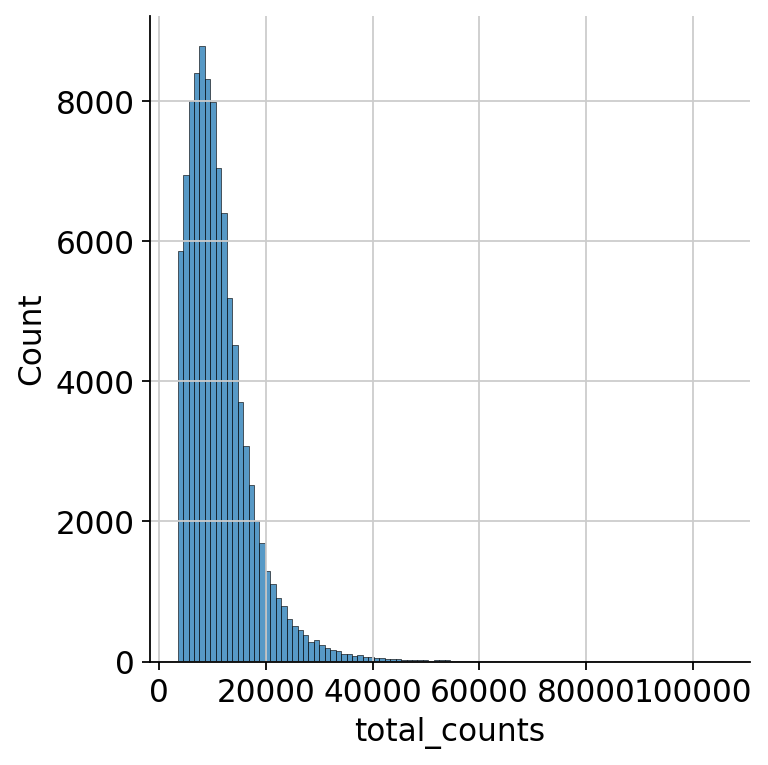

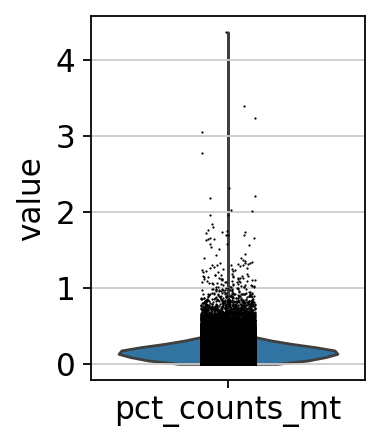

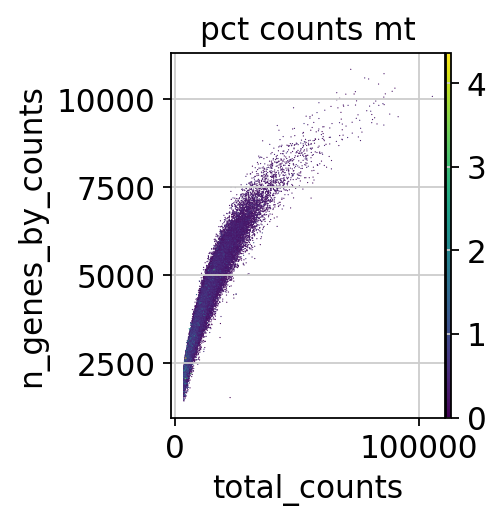

In [13]:
"""
MT_genes_to_ensemble_ids= {
    'MT-ND1'  : "ENSG00000198888",
    'MT-ND2'  : "ENSG00000198763",
    'MT-CO1'  : "ENSG00000198804",
    'MT-CO2'  : "ENSG00000198712",
    'MT-ATP8' : "ENSG00000228253",
    'MT-ATP6' : "ENSG00000198899",
    'MT-CO3'  : "ENSG00000198938",
    'MT-ND3'  : "ENSG00000198840",
    'MT-ND4L' : "ENSG00000212907",
    'MT-ND4'  : "ENSG00000198886",
    'MT-ND5'  : "ENSG00000198786",
    'MT-ND6'  : "ENSG00000198695",
    'MT-CYB'  : "ENSG00000198727"
}
adata.var["mt"] = adata.var_names.isin(MT_genes_to_ensemble_ids.values())

sc.pp.calculate_qc_metrics(
    adata, 
    qc_vars=["mt"], 
    inplace=True, 
    percent_top=[20], 
    log1p=True
)
"""
p1 = sns.displot(adata.obs["total_counts"], bins=100, kde=False)
p2 = sc.pl.violin(adata, "pct_counts_mt")
p3 = sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

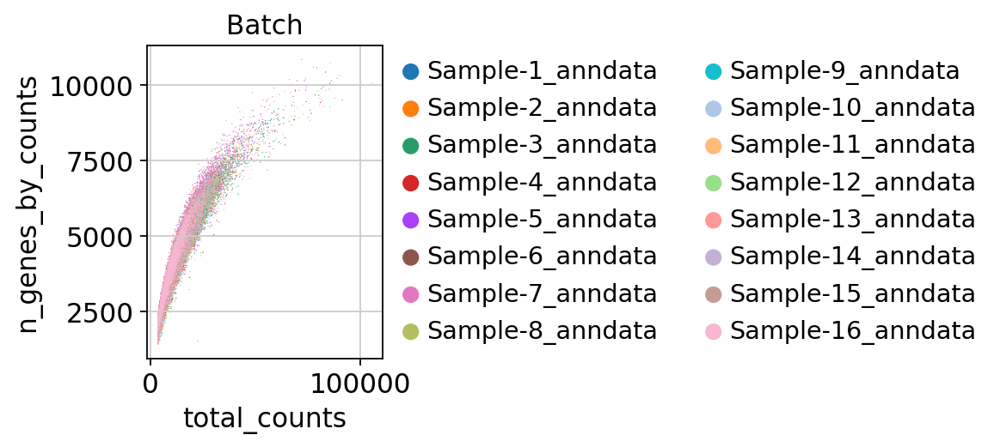

In [14]:
p1 = sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="Batch")

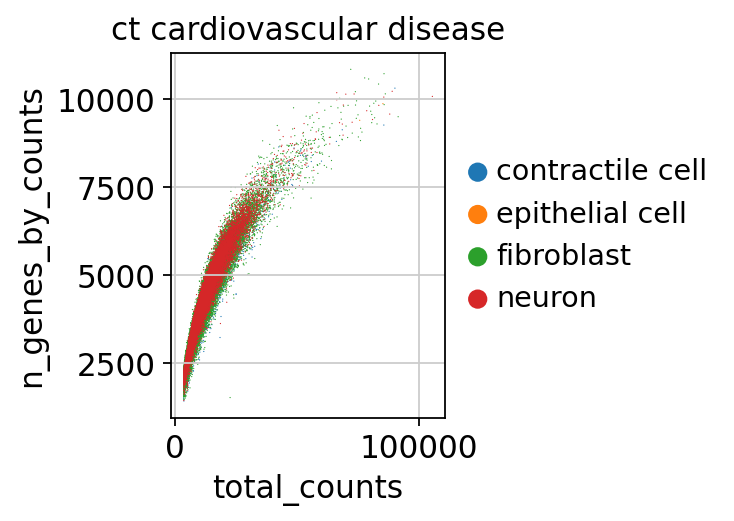

In [15]:
p1 = sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color='ct_cardiovascular_disease')

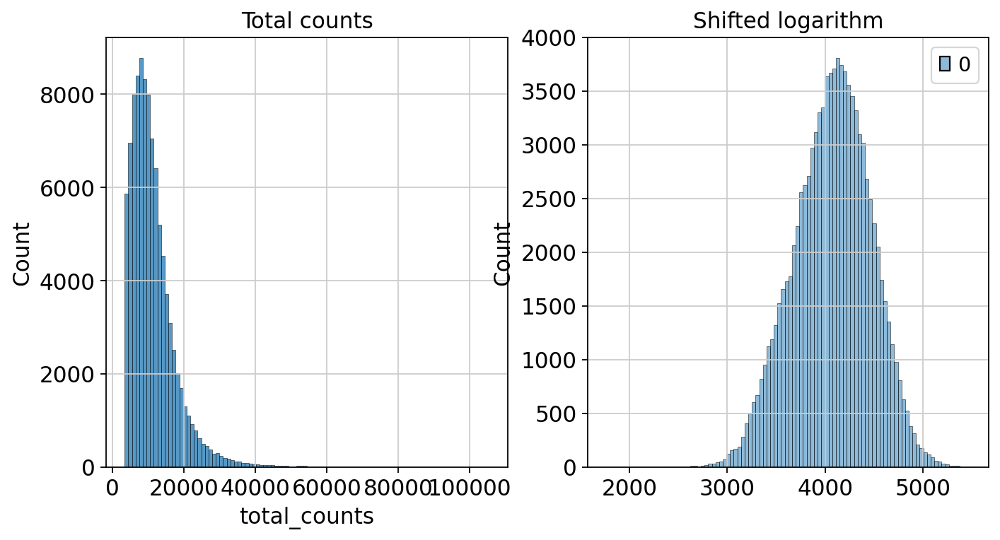

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
p1 = sns.histplot(adata.obs["total_counts"], bins=100, kde=False, ax=axes[0])
axes[0].set_title("Total counts")
p2 = sns.histplot(adata.layers["log1p_norm"].sum(1), bins=100, kde=False, ax=axes[1])
axes[1].set_title("Shifted logarithm")
plt.show()

In [17]:
hvg_df = adata.var[adata.var['highly_variable']]
print("Number of highly variable genes: " + str(len(hvg_df)))
display(hvg_df)

Number of highly variable genes: 4538


,n_cells,mt,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts,highly_variable,means,dispersions,dispersions_norm,gene_symbol
gene_id,,,,,,,,,,,,,
ENSG00000187634,244108,False,228469,0.218269,0.197431,85.561111,3.453713e+05,12.752378,True,0.183190,0.676542,1.026278,SAMD11
ENSG00000067606,219920,False,201751,0.212416,0.192615,87.249647,3.361095e+05,12.725195,True,0.156090,0.604093,0.828944,PRKCZ
ENSG00000142611,414351,False,368226,0.896723,0.640128,76.728683,1.418902e+06,14.165394,True,0.623036,1.988552,1.933675,PRDM16
ENSG00000196581,92719,False,84561,0.156694,0.145566,94.655875,2.479398e+05,12.420945,True,0.117234,1.685351,3.774021,AJAP1
ENSG00000236948,18796,False,17584,0.018273,0.018108,98.888718,2.891362e+04,10.272102,True,0.015336,1.042360,2.022673,AL365255.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
ENSG00000175894,31897,False,29107,0.045354,0.044355,98.160482,7.176375e+04,11.181149,True,0.037111,1.823440,4.150141,TSPEAR
ENSG00000197381,835144,False,756656,1.316344,0.839990,52.180505,2.082874e+06,14.549260,True,0.746943,1.246957,0.724099,ADARB1
ENSG00000182871,923021,False,817601,1.672479,0.983006,48.328875,2.646392e+06,14.788708,True,0.879932,1.381034,0.635962,COL18A1


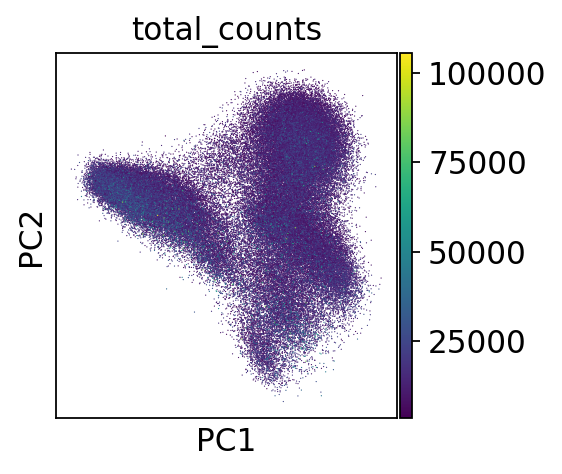

In [18]:
sc.pl.pca_scatter(adata, color="total_counts")

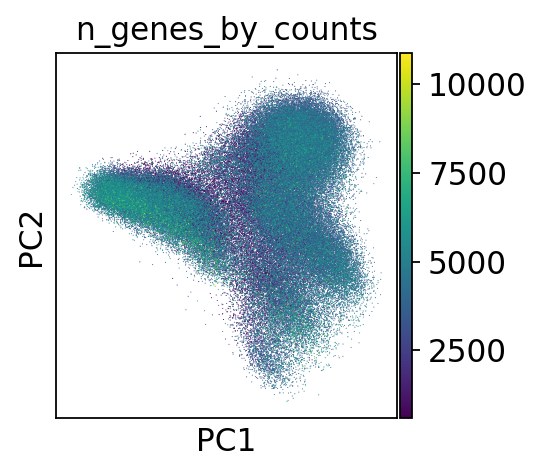

In [25]:
sc.pl.pca_scatter(adata, color="n_genes_by_counts")

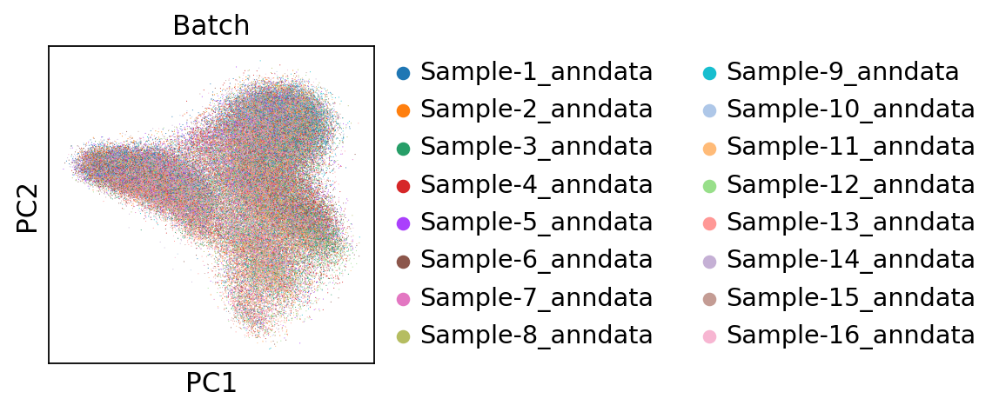

In [26]:
sc.pl.pca_scatter(adata, color="Batch")

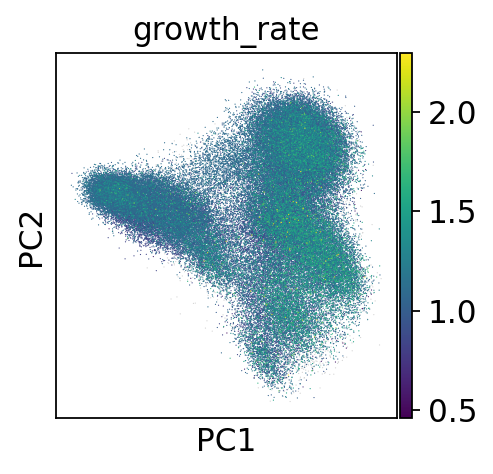

In [34]:
sc.pl.pca_scatter(adata, color="growth_rate")

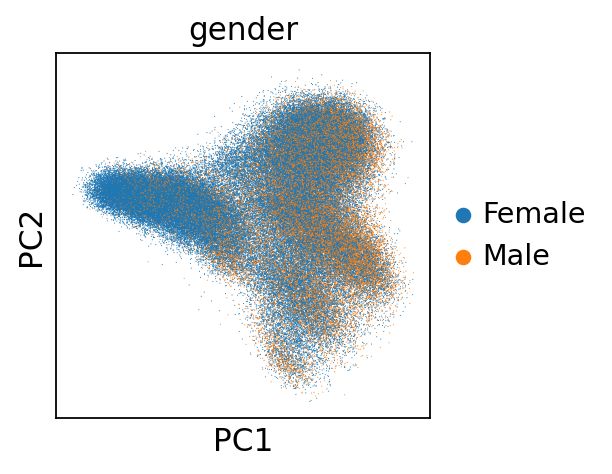

In [27]:
sc.pl.pca_scatter(adata, color='gender')

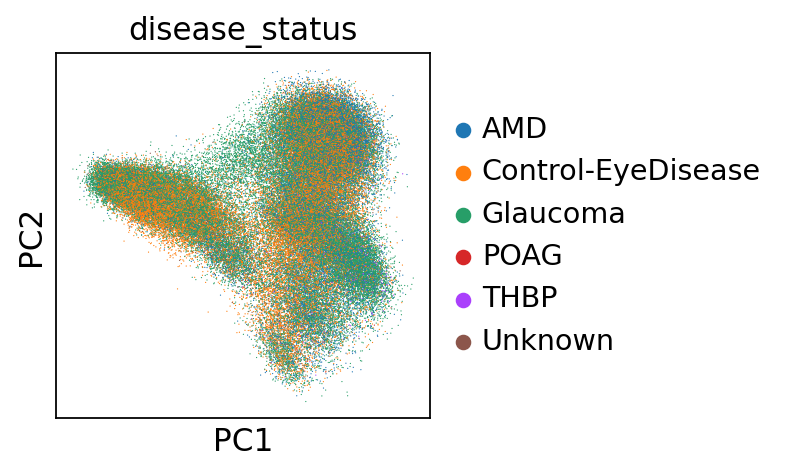

In [19]:
sc.pl.pca_scatter(adata, color='disease_status')

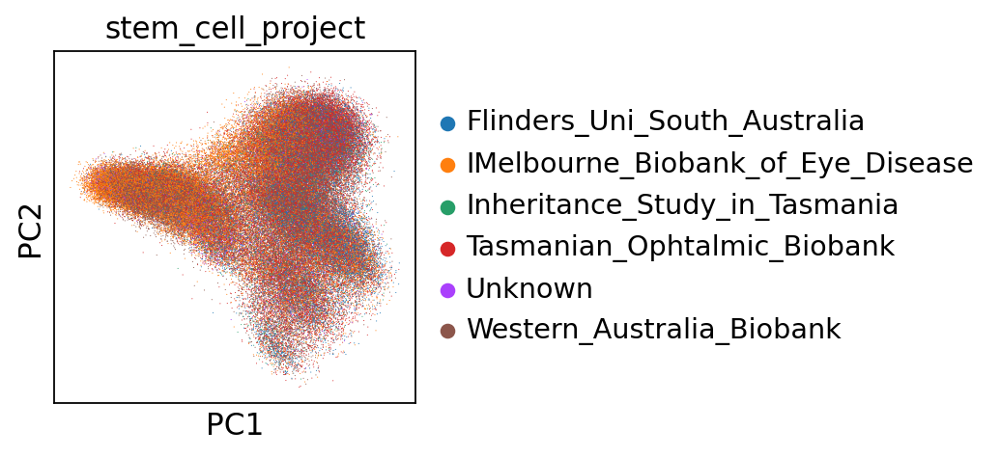

In [29]:
sc.pl.pca_scatter(adata, color='stem_cell_project')

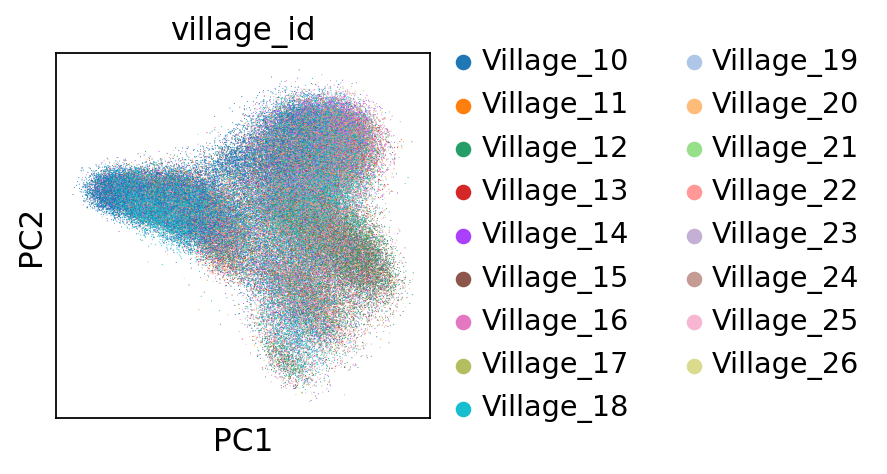

In [30]:
sc.pl.pca_scatter(adata, color='village_id')

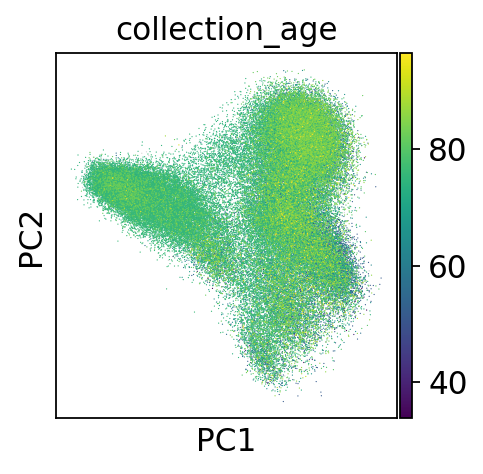

In [20]:
sc.pl.pca_scatter(adata, color='collection_age')

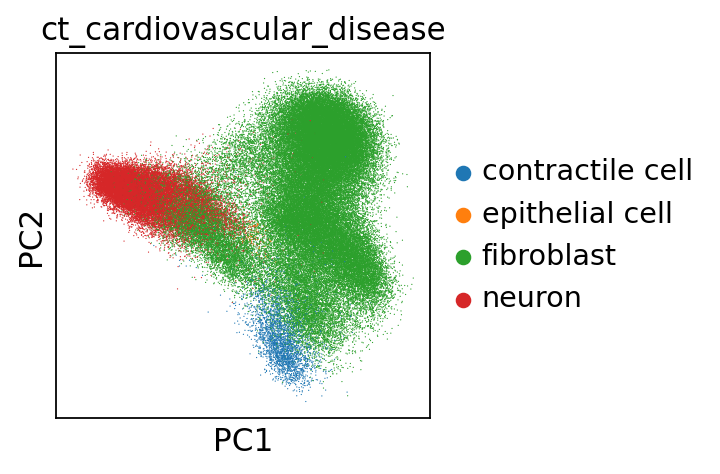

In [21]:
sc.pl.pca_scatter(adata, color='ct_cardiovascular_disease')

In [22]:
adata

AnnData object with n_obs × n_vars = 98894 × 35127
    obs: 'cell_id', 'counts', 'genes', 'totalReads', 'countedReads', 'mappedReads', 'geneReads', 'exonReads', 'intronReads', 'antisenseReads', 'mitoReads', 'countedMultiGeneReads', 'Saturation', 'mitoProp', 'PCR', 'RT', 'bead_bc', 'sample', 'flags', 'sample_id', 'Batch', 'Donor_ID', 'growth_rate', 'passage_number', 'village_id', 'village_id_2', 'maxi_village_id', 'maxi_village_id_2', 'collection_age', 'gender', 'ethnicity', 'disease_status', 'stem_cell_project', 'PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'Batch name', 'ct_cardiovascular_disease', 'n_genes', 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'S_score', 'G2M_score', 'phase', 'leiden_r0.1', 'leiden_r0.15', 'leiden_r0.18', 'leiden_r0.2'
    var: 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 't

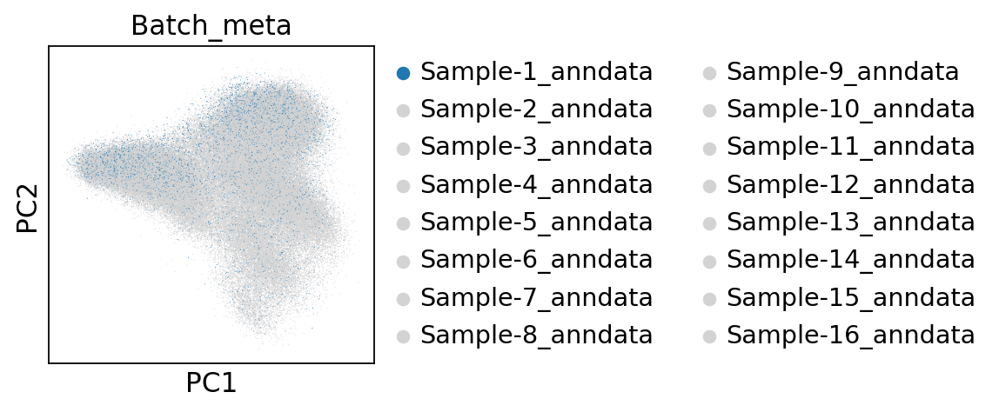

In [87]:
unique_batches = adata.obs["Batch_meta"].unique()
target = "Sample-1_anndata"
custom_palette = {
    batch: ("#1f77b4" if batch == target else "#d3d3d3") for batch in unique_batches
}
sc.pl.pca(adata, color="Batch_meta", palette=custom_palette)

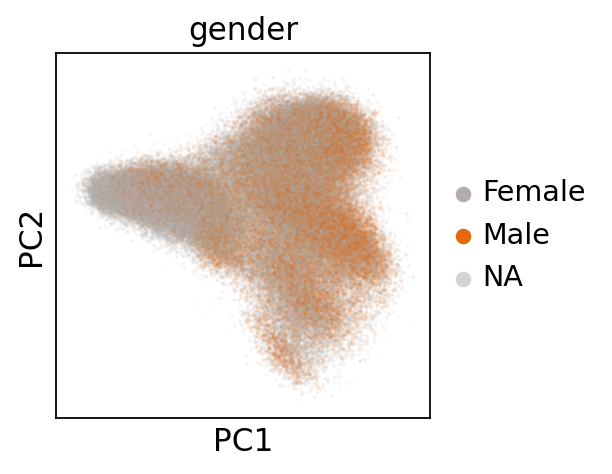

In [96]:
sc.pl.pca(
    adata, 
    color="gender", 
    groups=["Male", "Female"],  # Splits these out into individual subplots
    size=10,                    # Adjusts dot size so background cells don't bury the signal
    alpha=0.1,                  # Makes your target group pop
    show=True
)

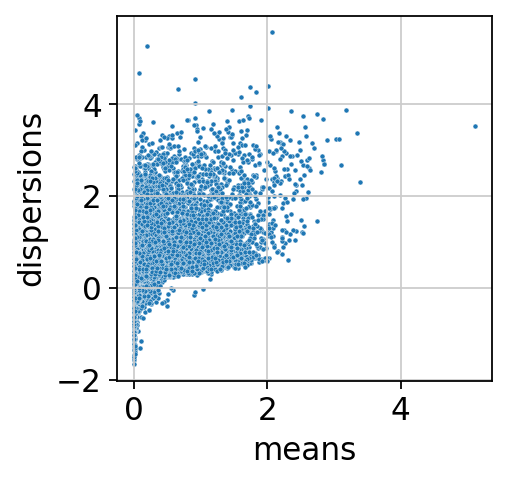

In [23]:
ax = sns.scatterplot(
    data=adata.var, x="means", y="dispersions", s=5
)
plt.show()

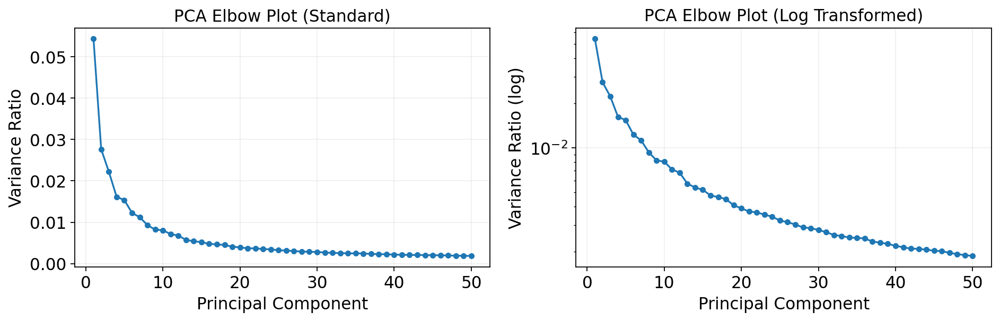

In [35]:
n_pcs = min(50, len(adata.uns['pca']['variance_ratio']))

# 2. Extract the variance ratios directly from the AnnData object
var_ratios = adata.uns['pca']['variance_ratio'][:n_pcs]
pcs = np.arange(1, n_pcs + 1)

# 3. Create the side-by-side figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# --- Plot 1: Standard (Linear) ---
ax1.plot(pcs, var_ratios, marker='o', linestyle='-', markersize=4, color='tab:blue')
ax1.set_title('PCA Elbow Plot (Standard)')
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Variance Ratio')
ax1.grid(True, alpha=0.3)

# --- Plot 2: Log Transformed ---
ax2.plot(pcs, var_ratios, marker='o', linestyle='-', markersize=4, color='tab:blue')
ax2.set_yscale('log') # This does the log transformation on the axis
ax2.set_title('PCA Elbow Plot (Log Transformed)')
ax2.set_xlabel('Principal Component')
ax2.set_ylabel('Variance Ratio (log)')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

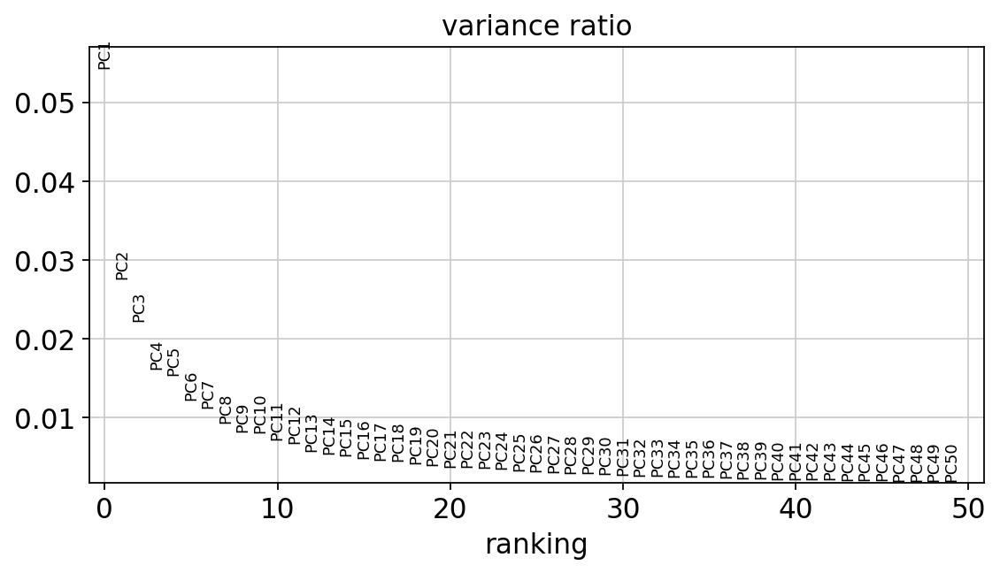

In [36]:
with plt.rc_context({"figure.figsize": (8, 4)}):
    sc.pl.pca_variance_ratio(
        adata, 
        log=False,      
        n_pcs=50,       
        show=True
    )

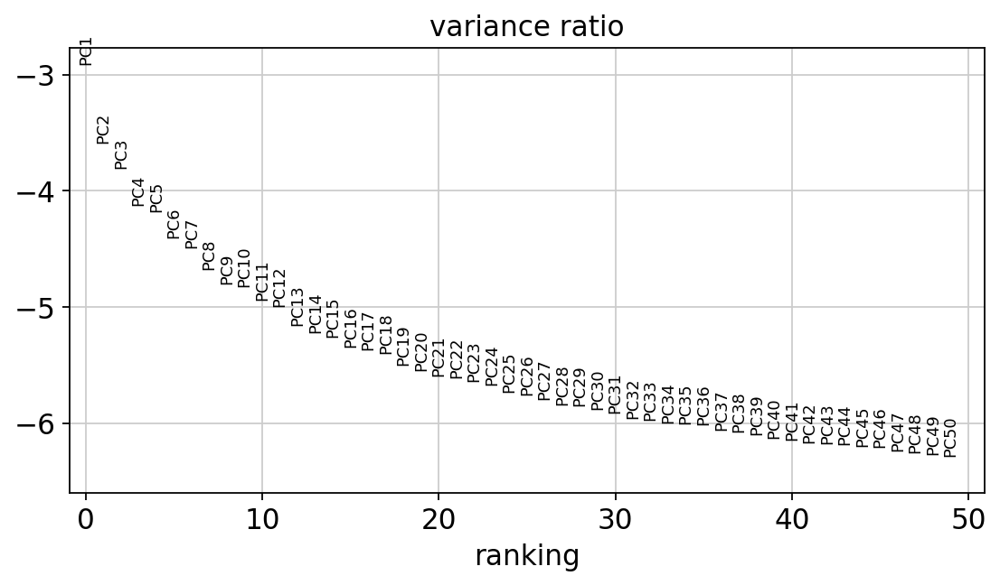

In [37]:
with plt.rc_context({"figure.figsize": (8, 4)}):
    sc.pl.pca_variance_ratio(
        adata, 
        log=True,      
        n_pcs=50,       
        show=True
    )

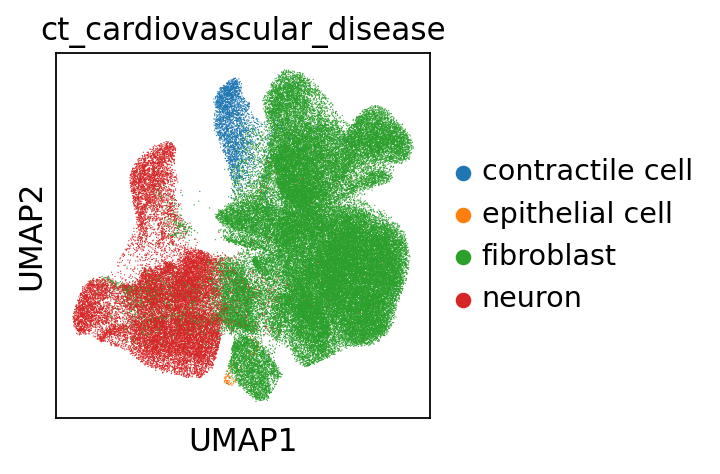

In [24]:
sc.pl.umap(
    adata,
    color= "ct_cardiovascular_disease",
    ncols=3,       # Adjust this to change how many plots appear per row
    wspace=0.4,    # Adds horizontal space so legends don't overlap
    show=True,
    layer="log1p_norm",
    vmax="p99"
)

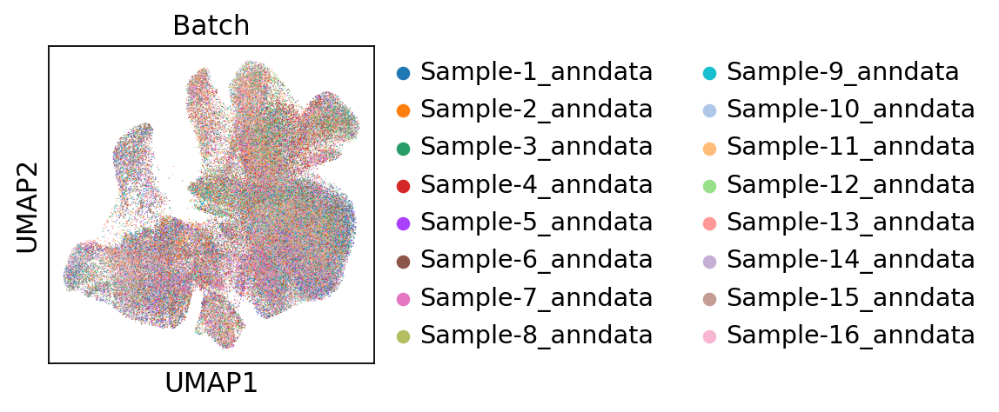

In [25]:
sc.pl.umap(
    adata,
    color= "Batch",
    ncols=3,       # Adjust this to change how many plots appear per row
    wspace=0.4,    # Adds horizontal space so legends don't overlap
    show=True,
    layer="log1p_norm",
    vmax="p99"
)

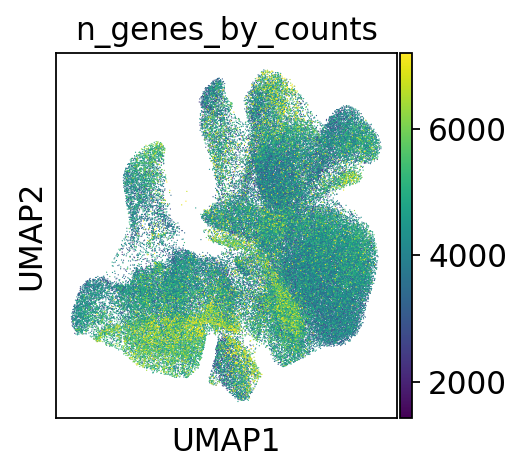

In [26]:
sc.pl.umap(
    adata,
    color= "n_genes_by_counts",
    ncols=3,       # Adjust this to change how many plots appear per row
    wspace=0.4,    # Adds horizontal space so legends don't overlap
    show=True,
    layer="total_counts",
    vmax="p99"
)

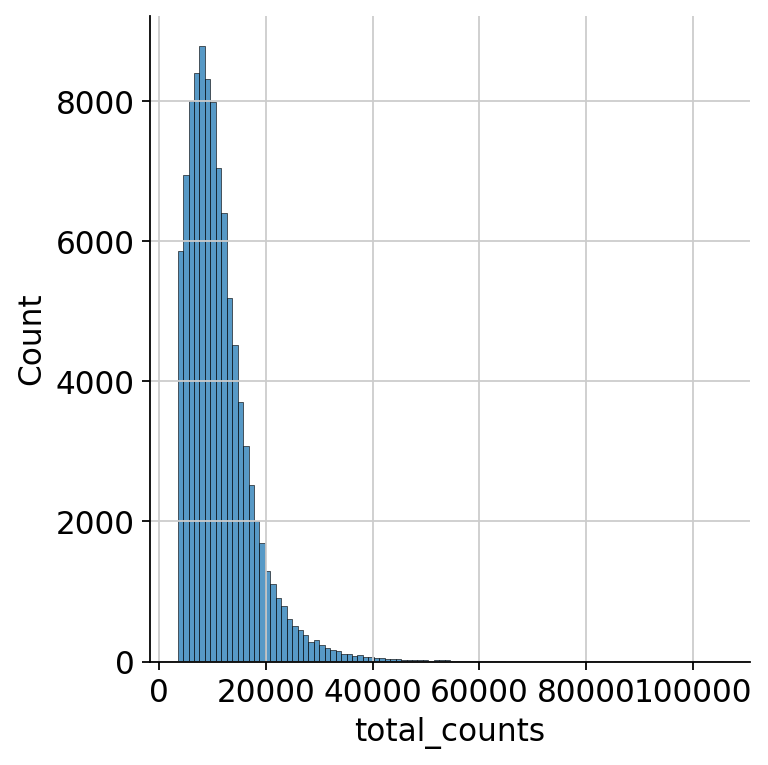

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set binrange to isolate cells with 2500 counts and less
p1 = sns.displot(
    adata.obs["total_counts"], 
    bins=100, 
    kde=False, 
    #binrange=(0, 100500)
)

# Explicitly set the x-axis visual limit to match
#p1.set(xlim=(40000, 100500))

# Display the plot in your notebook
plt.show()

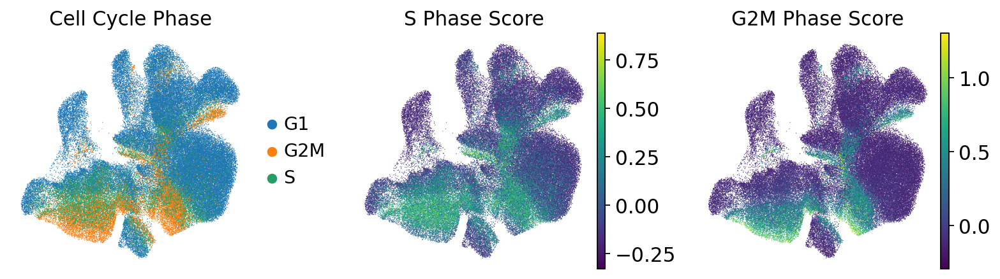

In [34]:
sc.pl.umap(
    adata, 
    color=['phase', 'S_score', 'G2M_score'],
    title=['Cell Cycle Phase', 'S Phase Score', 'G2M Phase Score'],
    color_map='viridis', # A clean sequential map for the continuous scores
    frameon=False,       # Clean background with no box borders
    wspace=0.3          # Adds comfortable spacing between the three panels
)

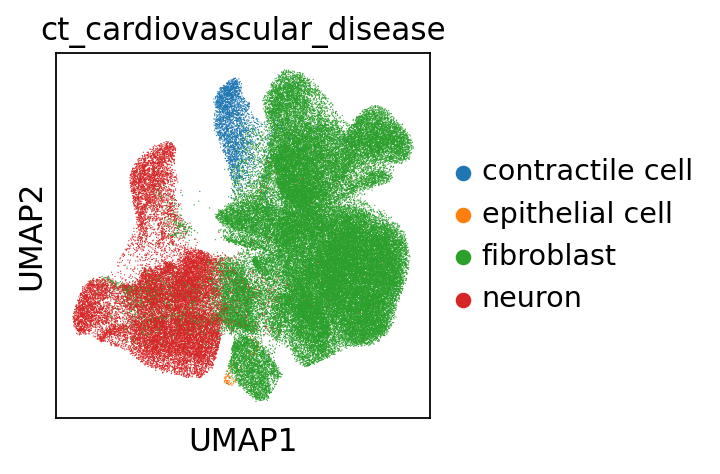

In [35]:
sc.pl.umap(
    adata,
    color= "ct_cardiovascular_disease",
    ncols=3,       # Adjust this to change how many plots appear per row
    wspace=0.4,    # Adds horizontal space so legends don't overlap
    show=True,
    layer="log1p_norm",
    vmax="p99"
)

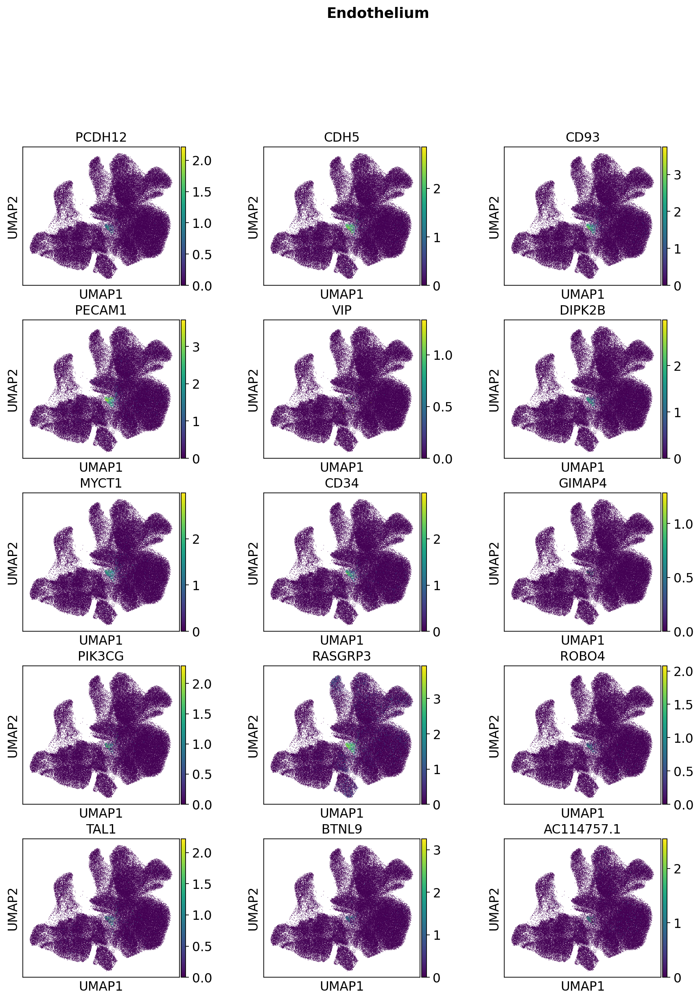

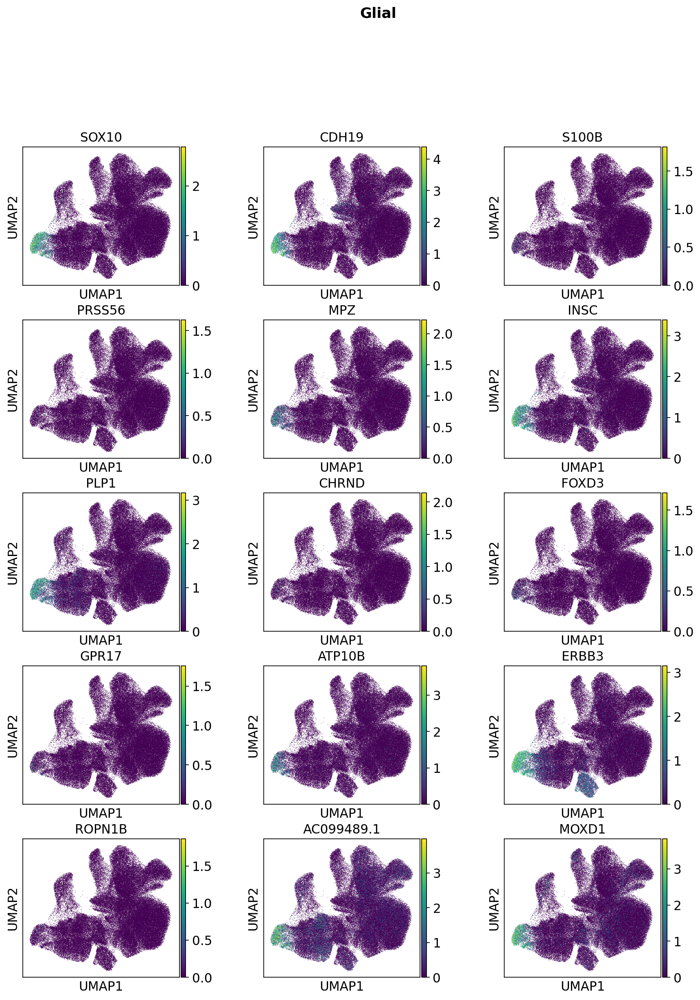

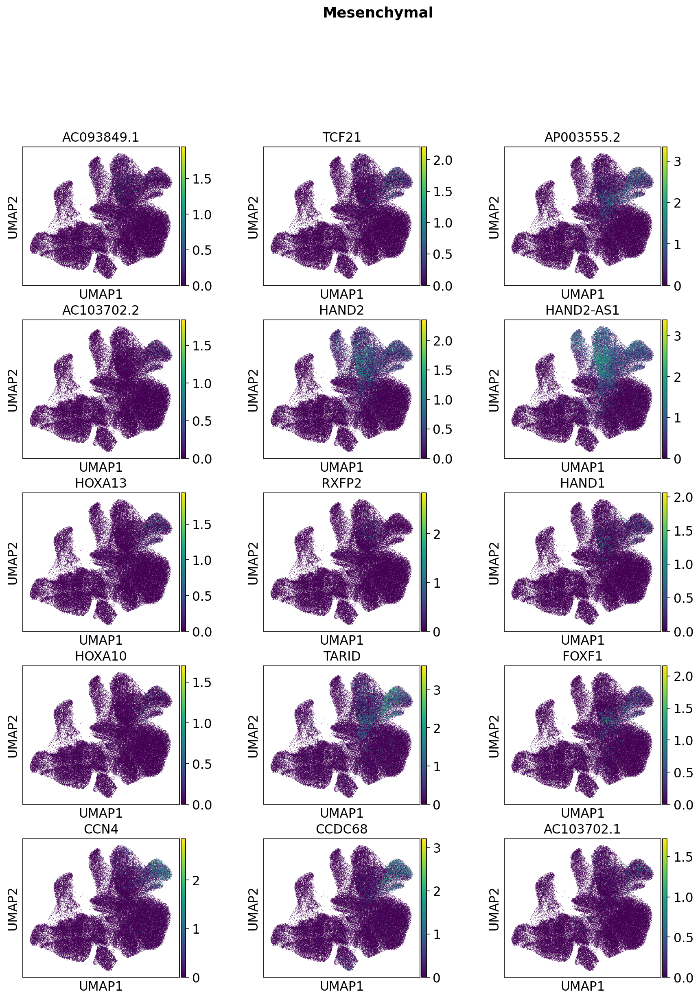

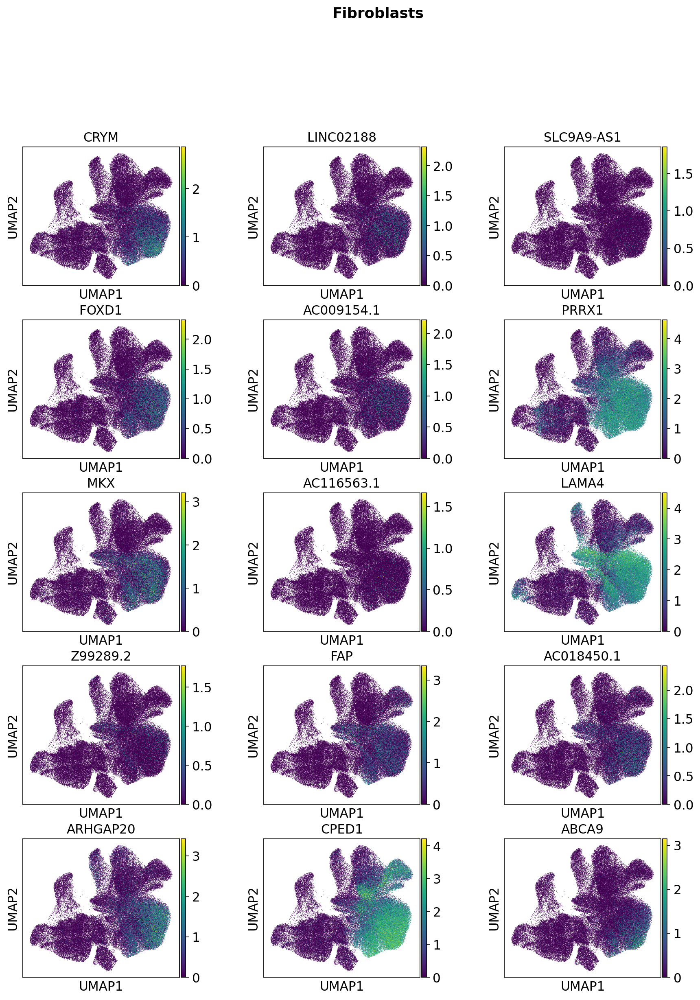

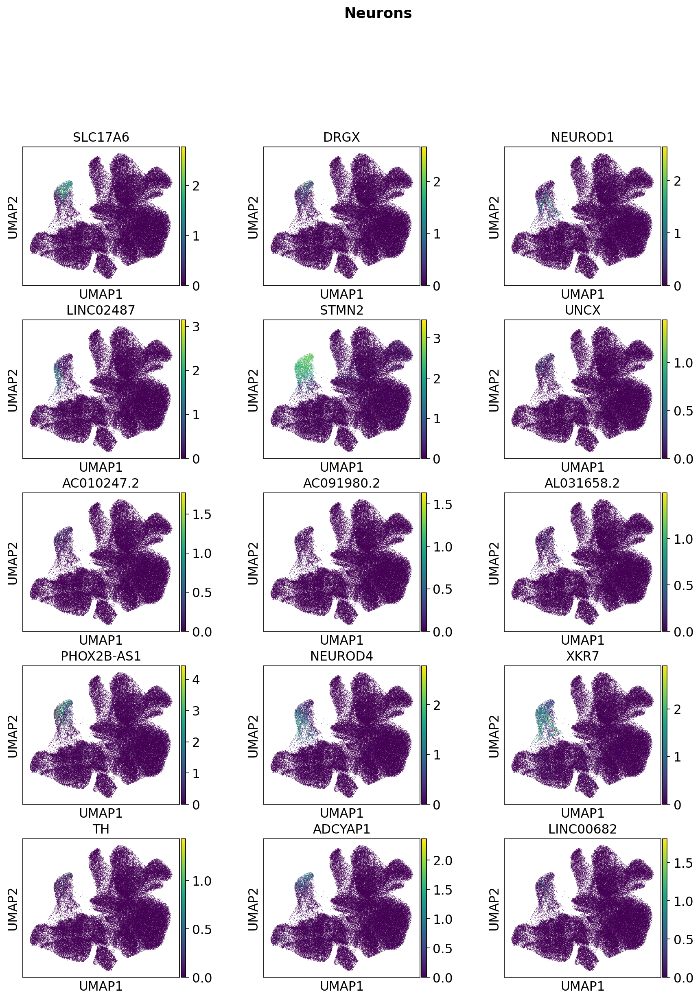

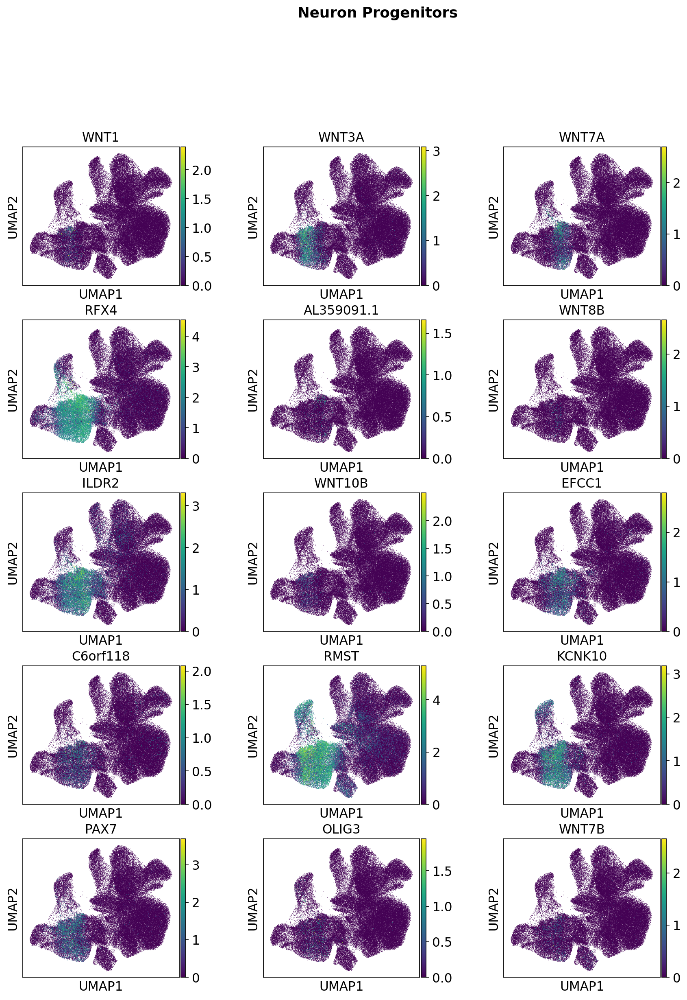

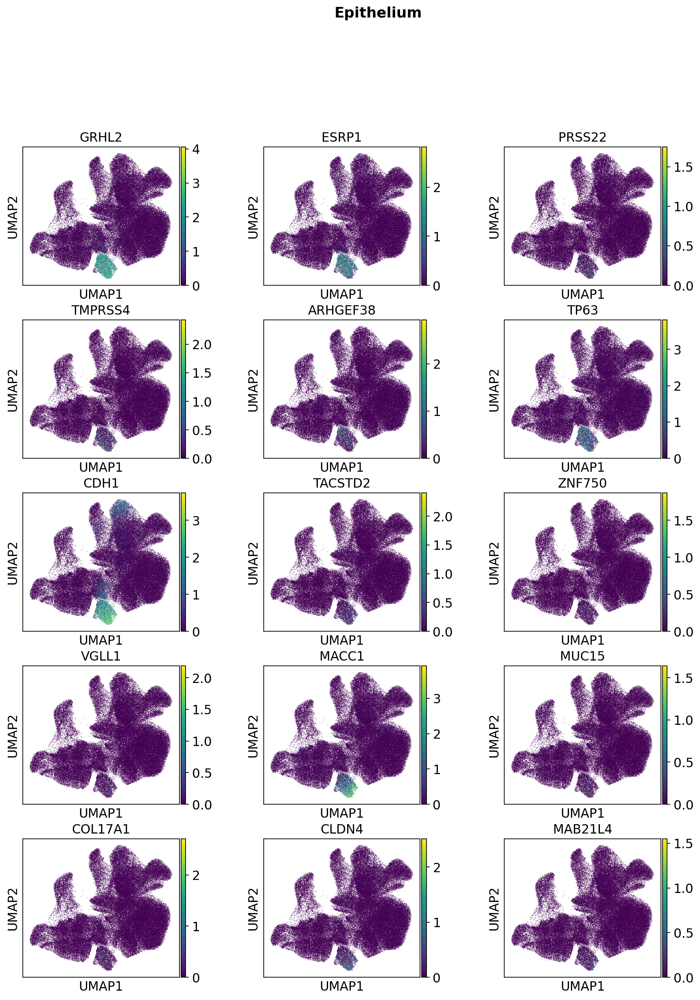

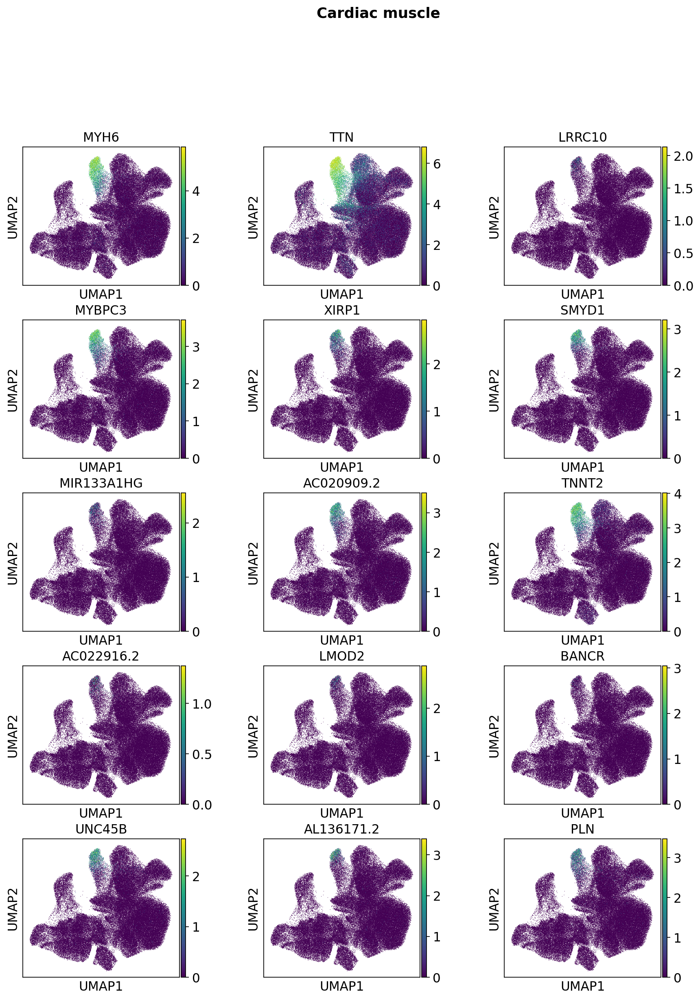

In [36]:
import matplotlib as mpl
marker_groups = {
    'Endothelium' : ['PCDH12', 'CDH5', 'CD93', 'PECAM1', 'VIP', 'DIPK2B', 'MYCT1', 'CD34', 'GIMAP4', 'PIK3CG', 'RASGRP3', 'ROBO4', 'TAL1', 'BTNL9', 'AC114757.1'],
    'Glial' : ['SOX10', 'CDH19', 'S100B', 'PRSS56', 'MPZ', 'INSC', 'PLP1', 'CHRND', 'FOXD3', 'GPR17', 'ATP10B', 'ERBB3', 'ROPN1B', 'AC099489.1', 'MOXD1'],
    'Mesenchymal' : ['AC093849.1', 'TCF21', 'AP003555.2', 'AC103702.2', 'HAND2', 'HAND2-AS1', 'HOXA13', 'RXFP2', 'HAND1', 'HOXA10', 'TARID', 'FOXF1', 'CCN4', 'CCDC68', 'AC103702.1'],
    'Fibroblasts' : ['CRYM', 'LINC02188', 'SLC9A9-AS1', 'FOXD1', 'AC009154.1', 'PRRX1', 'MKX', 'AC116563.1', 'LAMA4', 'Z99289.2', 'FAP', 'AC018450.1', 'ARHGAP20', 'CPED1', 'ABCA9'],
    'Neurons' : ['SLC17A6', 'DRGX', 'NEUROD1', 'LINC02487', 'STMN2', 'UNCX', 'AC010247.2', 'AC091980.2', 'AL031658.2', 'PHOX2B-AS1', 'NEUROD4', 'XKR7', 'TH', 'ADCYAP1', 'LINC00682'],
    'Neuron Progenitors' : ['WNT1', 'WNT3A', 'WNT7A', 'RFX4', 'AL359091.1', 'WNT8B', 'ILDR2', 'WNT10B', 'EFCC1', 'C6orf118', 'RMST', 'KCNK10', 'PAX7', 'OLIG3', 'WNT7B'],
    'Epithelium' : ['GRHL2', 'ESRP1', 'PRSS22', 'TMPRSS4', 'ARHGEF38', 'TP63', 'CDH1', 'TACSTD2', 'ZNF750', 'VGLL1', 'MACC1', 'MUC15', 'COL17A1', 'CLDN4', 'MAB21L4'],
    'Cardiac muscle' : ['MYH6', 'TTN', 'LRRC10', 'MYBPC3', 'XIRP1', 'SMYD1', 'MIR133A1HG', 'AC020909.2', 'TNNT2', 'AC022916.2', 'LMOD2', 'BANCR', 'UNC45B', 'AL136171.2', 'PLN']
}

gene_to_ensembl = {v: k for k, v in ensembl_to_gene.items()}

# 3. Simple expression plotting loop
for group_name, genes in marker_groups.items():
    # Gather matching Ensembl keys from your dictionary that exist in your matrix
    # (Note: Using .get() ensures it handles lowercase variants like 'Hes1' safely if they are uppercase in your dict)
    ensembl_features = [
        gene_to_ensembl.get(gene) for gene in genes 
        if gene_to_ensembl.get(gene) in adata.var_names
    ]
    
    # Create matching titles using the human-readable gene names for the subplots
    plot_titles = [gene for gene in genes if gene_to_ensembl.get(gene) in adata.var_names]
    
    if not ensembl_features:
        print(f"Skipping group '{group_name}': No matching genes found in the dataset matrix.")
        continue
        
    # Generate the standard expression plots for this specific list
    sc.pl.umap(
        adata,
        color=ensembl_features,
        title=plot_titles,
        ncols=3,
        wspace=0.4,
        show=False,
        layer="log1p_norm"
    )
    
    # Apply your group name as the overarching panel title
    plt.suptitle(group_name, y=1.02, fontsize=16, fontweight='bold')
    plt.subplots_adjust(top=1)  # Keeps the title from overlapping the top row
    
    # Explicitly render in the notebook
    plt.show()


In [48]:
save_path="/g/data/wy83/cardiotoxicity/analysis/anndata/full_data_analysis/dim_reduction/results/test_v2"
umap_df = pd.DataFrame(
    adata.obsm['X_umap'],
    index=adata.obs_names,
    columns=['UMAP_1', 'UMAP_2']
)
csv_file = f"{save_path}/umap_coords_{n_pcs}_PCs_full.csv"
umap_df.to_csv(csv_file)
print(f"Saved: {csv_file}")

Saved: /g/data/wy83/cardiotoxicity/analysis/anndata/full_data_analysis/dim_reduction/results/test_v2/umap_coords_11_PCs_full.csv


### Leiden clusterings

In [43]:
adata

AnnData object with n_obs × n_vars = 135240 × 23845
    obs: 'cell_id', 'counts', 'genes', 'totalReads', 'countedReads', 'mappedReads', 'geneReads', 'exonReads', 'intronReads', 'antisenseReads', 'mitoReads', 'countedMultiGeneReads', 'Saturation', 'mitoProp', 'PCR', 'RT', 'bead_bc', 'sample', 'flags', 'sample_id', 'Batch', 'Donor_ID', 'growth_rate', 'passage_number', 'village_id', 'village_id_2', 'maxi_village_id', 'maxi_village_id_2', 'collection_age', 'gender', 'ethnicity', 'disease_status', 'stem_cell_project', 'PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'Batch name', 'ct_cardiovascular_disease', 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'S_score', 'G2M_score', 'phase', 'leiden_r0.1', 'leiden_r0.15', 'leiden_r0.18', 'leiden_r0.2'
    var: 'n_cells', 'n_counts', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', '

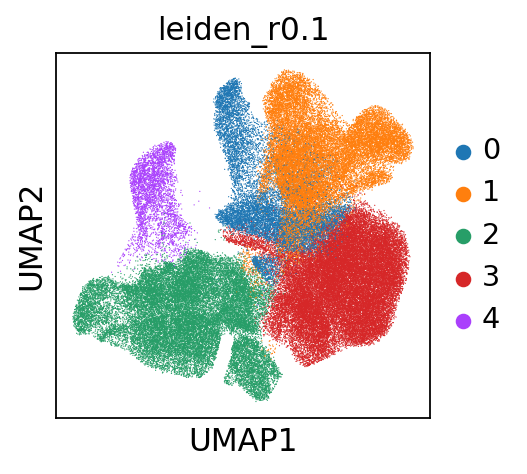

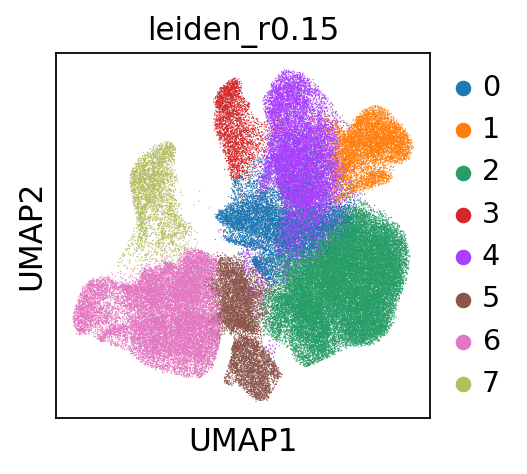

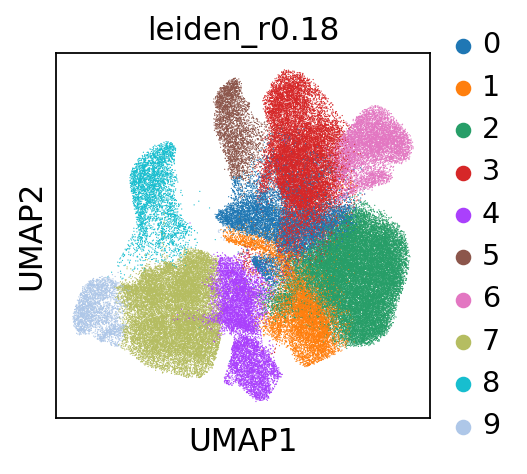

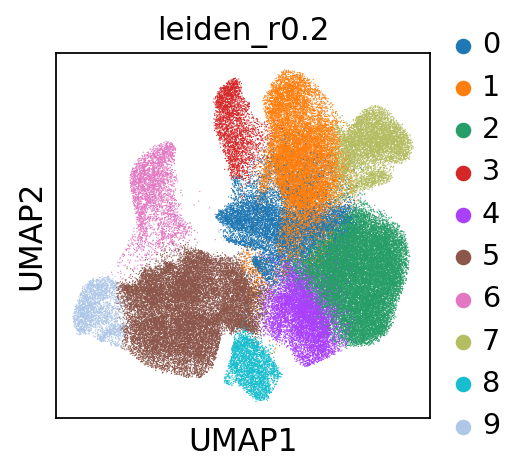

In [37]:
sc.pl.umap(
    adata,
    color= "leiden_r0.1",
    show=True,
)
sc.pl.umap(
    adata,
    color= "leiden_r0.15",
    show=True,
)
sc.pl.umap(
    adata,
    color= "leiden_r0.18",
    show=True,
)
sc.pl.umap(
    adata,
    color= "leiden_r0.2",
    show=True,
)


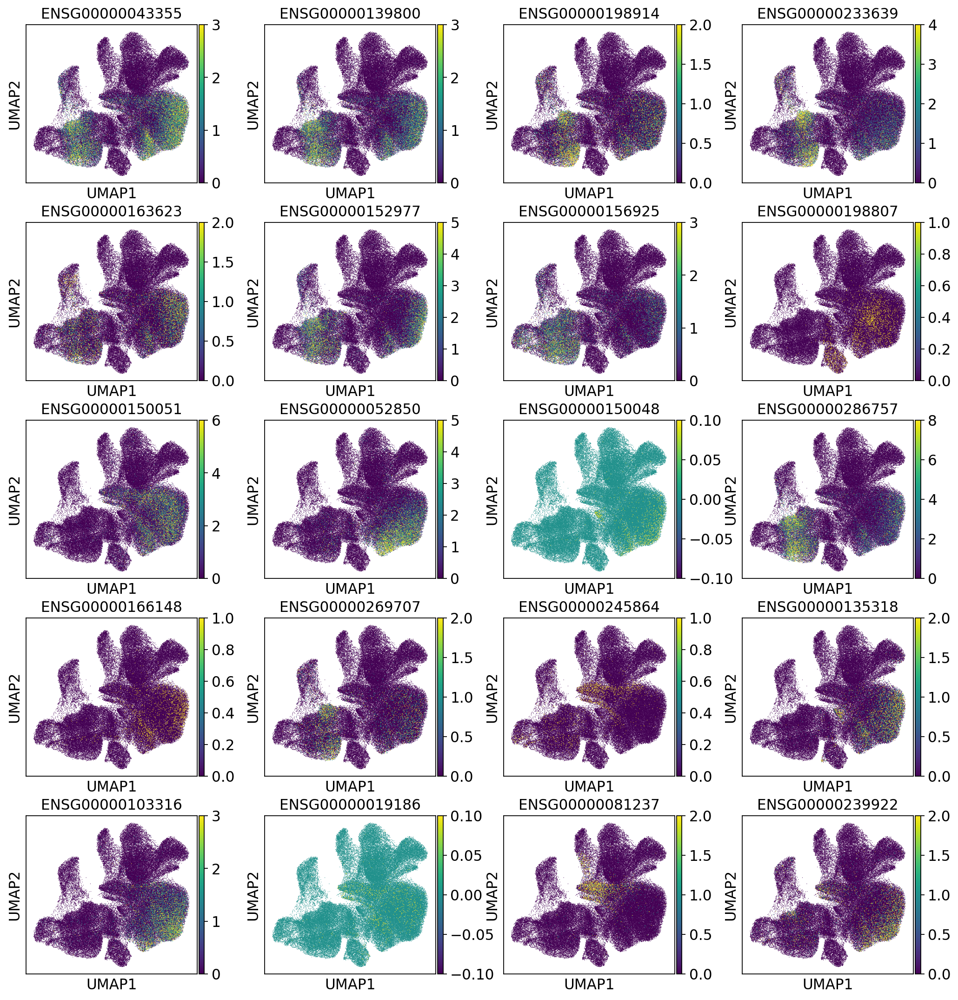

In [31]:
umap_features= filtered_deg_df['gene'].head(20)
sc.pl.umap(
    adata,
    color= umap_features,
    show=True,
    vmax="p99"
)

### Making final cell type annotation column

In [32]:
adata

AnnData object with n_obs × n_vars = 99227 × 35077
    obs: 'cell_id', 'counts', 'genes', 'totalReads', 'countedReads', 'mappedReads', 'geneReads', 'exonReads', 'intronReads', 'antisenseReads', 'mitoReads', 'countedMultiGeneReads', 'Saturation', 'mitoProp', 'PCR', 'RT', 'bead_bc', 'sample', 'flags', 'sample_id', 'Batch', 'Donor_ID', 'growth_rate', 'passage_number', 'village_id', 'village_id_2', 'maxi_village_id', 'maxi_village_id_2', 'collection_age', 'gender', 'ethnicity', 'disease_status', 'stem_cell_project', 'PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'Batch name', 'ct_cardiovascular_disease', 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'leiden_r0.1', 'leiden_r0.15', 'leiden_r0.18', 'leiden_r0.2'
    var: 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_v

In [38]:
## Missing epithelial
cluster_mapping_r02 = {
    '0': 'Fibroblasts',
    '1': 'Mesenchymal',
    '2': 'Fibroblasts',
    '3': 'Cardiac muscle',
    '4': 'Fibroblasts',
    '5': 'Neuron Progenitor',
    '6': 'Neuron',
    '7': 'Mesenchymal',
    '8': 'Epithelial',
    '9': 'Glia / Glia progenitor',
    #'10': 'Endothelium' missing, relly small cluster 
}


adata.obs['cell_type'] = adata.obs['leiden_r0.2'].map(cluster_mapping_r02)
#is_endothelial = adata.obs['leiden_r0.18'] == '0'
#adata.obs.loc[is_endothelial, 'cell_type'] = 'Endothelial'

adata.obs['cell_type'] = adata.obs['cell_type'].astype('category')
print("New Cell Type Annotation Distribution:")
print(adata.obs['cell_type'].value_counts())

New Cell Type Annotation Distribution:
cell_type
Fibroblasts               42031
Mesenchymal               23312
Neuron Progenitor         21198
Neuron                     3541
Epithelial                 3169
Cardiac muscle             3023
Glia / Glia progenitor     2620
Name: count, dtype: int64


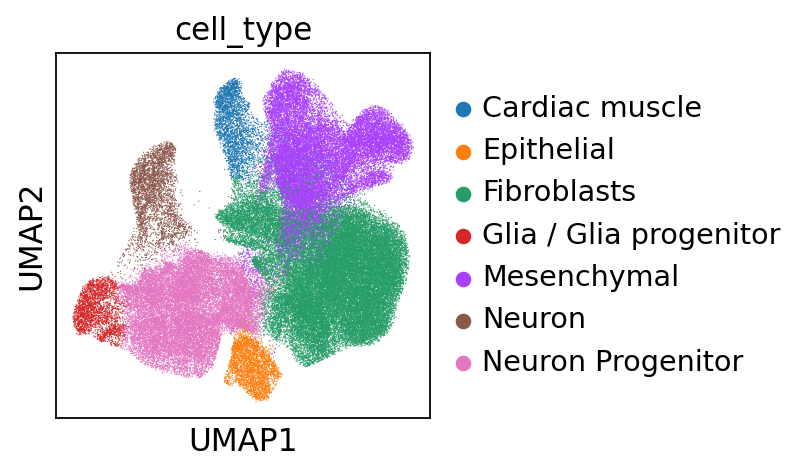

In [39]:
sc.pl.umap(
    adata,
    color= 'cell_type',
    show=True
)

### Ploting donor proportions per cell type

Note: scRNAseq data is compositional!!

In [40]:
sample_exposure = {
    "Sample-1_anndata" : "DMSO",
    "Sample-2_anndata" : "Afatinib",
    "Sample-3_anndata" : "Bosutinib",
    "Sample-4_anndata" : "Ceritinib",
    "Sample-5_anndata" : "Clozapine",
    "Sample-6_anndata" : "Crizotinib",
    "Sample-7_anndata" : "Doxorubicin",
    "Sample-8_anndata" : "Gefitinib",
    "Sample-9_anndata" : "Ibrutinib",
    "Sample-10_anndata" : "Olazapine",
    "Sample-11_anndata" : "Ponatinib",
    "Sample-12_anndata" : "Quetiapine",
    "Sample-13_anndata" : "Regorafenib",
    "Sample-14_anndata" : "Sorafenib",
    "Sample-15_anndata" : "Sunitinib",
    "Sample-16_anndata" : "Vandetanib"
}

In [9]:
import os
import pandas as pd
import anndata
from typing import Optional, Dict

def generate_proportion_df(
    adata: anndata.AnnData, 
    x_key: str, 
    stack_key: str, 
    split_key: Optional[str] = None,
    x_mapping: Optional[Dict[str, str]] = None,
    stack_mapping: Optional[Dict[str, str]] = None,
    split_mapping: Optional[Dict[str, str]] = None,
    save_path: Optional[str] = None
) -> pd.DataFrame:
    """
    Calculates cell counts and 100% normalized percentages for all category combinations.
    Saves the resulting long-form DataFrame as a CSV using the base name of save_path.
    """
    # 1. Gather active columns
    keep_cols = [x_key, stack_key]
    if split_key:
        keep_cols.append(split_key)
        
    df = adata.obs[keep_cols].copy()
    
    # 2. Convert to string and apply user-provided dictionary mappings
    df[x_key] = df[x_key].astype(str)
    if x_mapping:
        df[x_key] = df[x_key].replace(x_mapping)
        
    df[stack_key] = df[stack_key].astype(str)
    if stack_mapping:
        df[stack_key] = df[stack_key].replace(stack_mapping)
        
    if split_key:
        df[split_key] = df[split_key].astype(str)
        if split_mapping:
            df[split_key] = df[split_key].replace(split_mapping)
            
    # 3. Create cross-tabulations to match plotting mathematics
    index_structure = [df[x_key], df[split_key]] if split_key else df[x_key]
    
    count_table = pd.crosstab(index=index_structure, columns=df[stack_key])
    proportion_table = count_table.div(count_table.sum(axis=1), axis=0) * 100
    
    # 4. Flatten the tables into clean long-form rows
    count_long = count_table.stack().reset_index(name='cell_count')
    proportion_long = proportion_table.stack().reset_index(name='percentage')
    
    # 5. Combine counts and percentages into a unified dataframe
    result_df = count_long.copy()
    result_df['percentage'] = proportion_long['percentage']
    
    # 6. Save logic: Extract the base path and swap the extension to .csv
    if save_path is not None:
        base_path, _ = os.path.splitext(save_path)
        csv_path = base_path + '.csv'
        
        directory = os.path.dirname(csv_path)
        if directory and not os.path.exists(directory):
            os.makedirs(directory)
            
        result_df.to_csv(csv_path, index=False)
        print(f"Dataframe saved successfully to: {csv_path}")
        
    return result_df

In [10]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import anndata
from typing import Optional, Tuple, Dict

def plot_composition_bar(
    adata: anndata.AnnData, 
    x_key: str, 
    stack_key: str, 
    x_mapping: Optional[Dict[str, str]] = None,
    stack_mapping: Optional[Dict[str, str]] = None,
    figsize: Tuple[int, int] = (10, 6),
    save_path: Optional[str] = None,
    show: bool = True
):
    # --- NEW: Call external function to generate and save the CSV data table ---
    _ = generate_proportion_df(
        adata=adata, x_key=x_key, stack_key=stack_key, 
        x_mapping=x_mapping, stack_mapping=stack_mapping, save_path=save_path
    )
    
    # (Rest of the plotting logic remains exactly the same as before)
    if x_key not in adata.obs.columns or stack_key not in adata.obs.columns:
        raise ValueError("Keys not found in adata.obs")
    df = adata.obs[[x_key, stack_key]].copy()
    color_key = f'{stack_key}_colors'
    has_scanpy_colors = color_key in adata.uns
    custom_order = None
    if has_scanpy_colors and hasattr(adata.obs[stack_key], 'cat'):
        orig_categories = list(adata.obs[stack_key].cat.categories.astype(str))
        custom_order = [stack_mapping.get(cat, cat) for cat in orig_categories] if stack_mapping else orig_categories
    df[x_key] = df[x_key].astype(str).replace(x_mapping) if x_mapping else df[x_key].astype(str)
    df[stack_key] = df[stack_key].astype(str).replace(stack_mapping) if stack_mapping else df[stack_key].astype(str)
    count_table = pd.crosstab(df[x_key], df[stack_key])
    proportion_table = count_table.div(count_table.sum(axis=1), axis=0) * 100
    if custom_order:
        custom_order = [c for c in custom_order if c in proportion_table.columns]
        proportion_table = proportion_table[custom_order]
    fig, ax = plt.subplots(figsize=figsize, dpi=100)
    if has_scanpy_colors:
        ax = proportion_table.plot(kind='bar', stacked=True, ax=ax, color=list(adata.uns[color_key]))
    else:
        ax = proportion_table.plot(kind='bar', stacked=True, ax=ax)
    ax.set_ylabel('Percentage (%)')
    ax.set_xlabel(x_key)
    ax.set_title(f'Relative Abundance of {stack_key} by {x_key}')
    plt.xticks(rotation=45, ha='right')
    legend = ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title=stack_key)
    plt.tight_layout()
    fig.subplots_adjust(right=0.82)
    if save_path is not None:
        plt.savefig(save_path, bbox_inches='tight', bbox_extra_artists=(legend,), dpi=300)
        print(f"Figure saved successfully to: {save_path}")
    if show: plt.show()
    else: plt.close(fig)

#plot_composition_bar(
#    adata=adata,
#    x_key='batch', 
#    stack_key='leiden',
#    x_mapping=sample_exposure,
#    stack_mapping=leiden_res0_15_celltypes,
#    save_path='plots/exposure_vs_celltype.png'
#)

Dataframe saved successfully to: /g/data/wy83/cardiotoxicity/analysis/anndata/test_data_analysis/dim_reduction/exposure_vs_celltype_proportions.csv
Figure saved successfully to: /g/data/wy83/cardiotoxicity/analysis/anndata/test_data_analysis/dim_reduction/exposure_vs_celltype_proportions.png


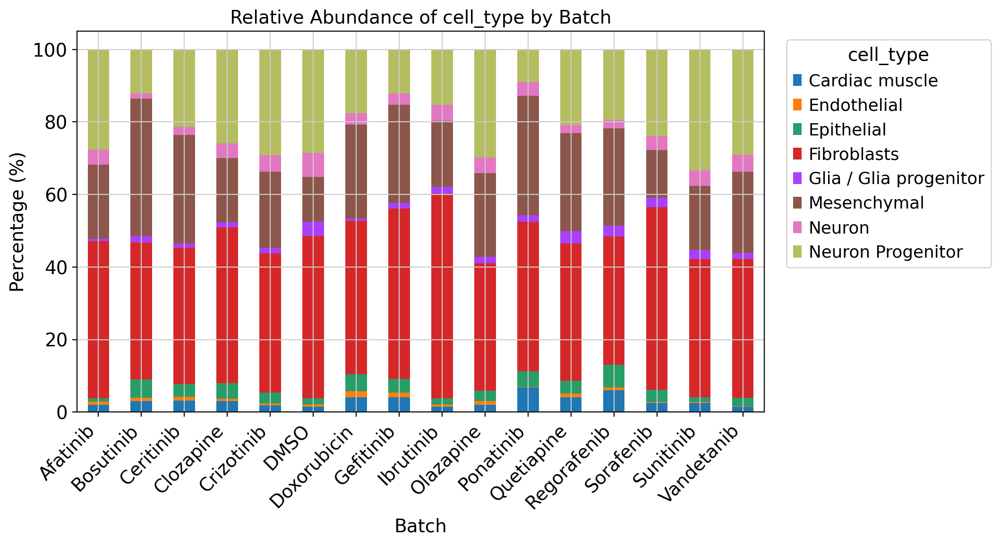

In [40]:
plot_composition_bar(
    adata=adata,
    x_key='Batch', 
    stack_key='cell_type',
    x_mapping=sample_exposure,
    save_path='/g/data/wy83/cardiotoxicity/analysis/anndata/test_data_analysis/dim_reduction/exposure_vs_celltype_proportions.png'
)

/home/913/xd5809/tmp/ipykernel_3905880/3730955996.py:101: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


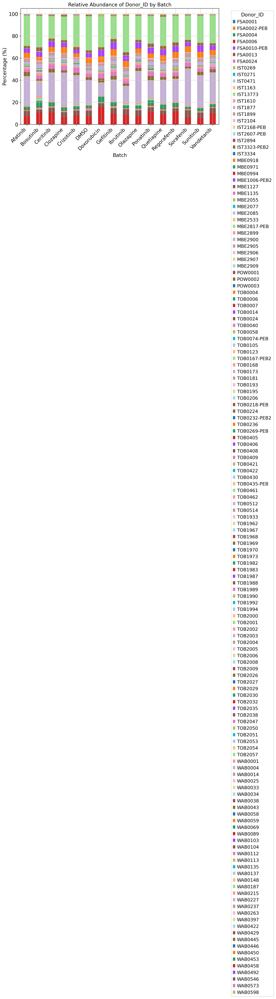

In [29]:
plot_composition_bar(
    adata=adata,
    x_key='Batch', 
    stack_key='Donor_ID',
    x_mapping=sample_exposure
)

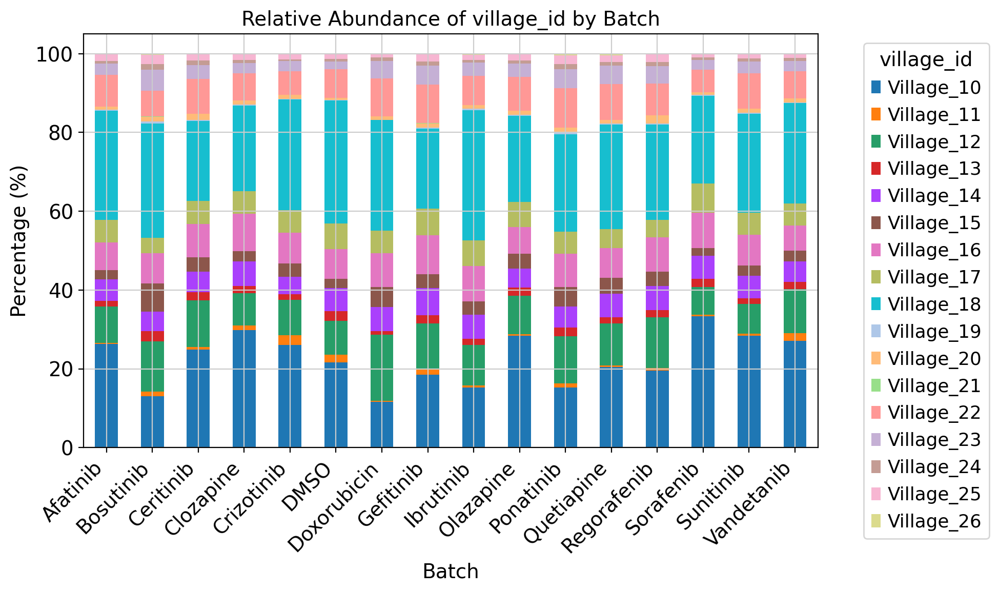

In [30]:
plot_composition_bar(
    adata=adata,
    x_key='Batch', 
    stack_key='village_id',
    x_mapping=sample_exposure
)

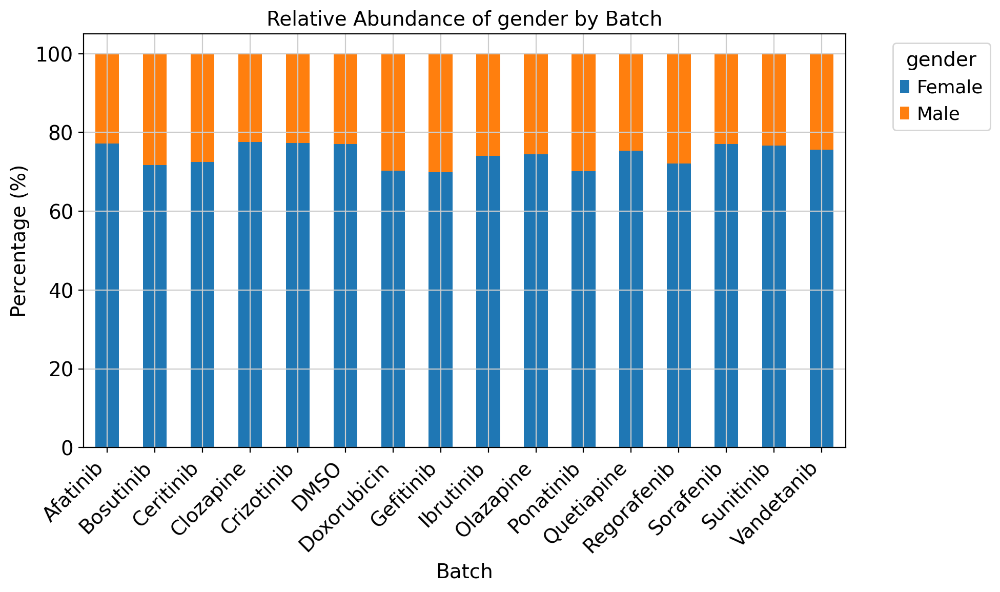

In [31]:
plot_composition_bar(
    adata=adata,
    x_key='Batch', 
    stack_key='gender',
    x_mapping=sample_exposure
)

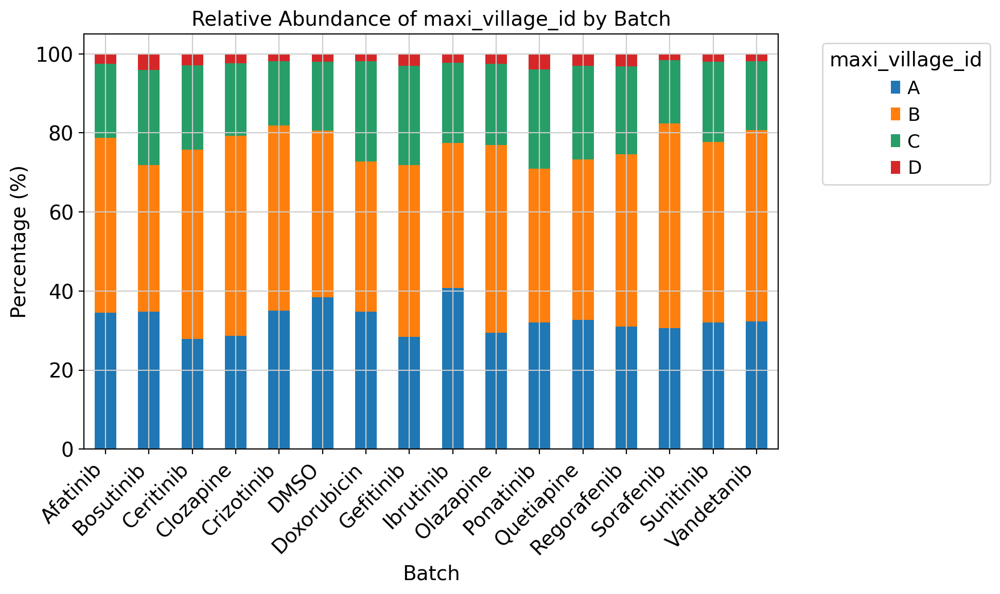

In [33]:
plot_composition_bar(
    adata=adata,
    x_key='Batch', 
    stack_key='maxi_village_id',
    x_mapping=sample_exposure
)

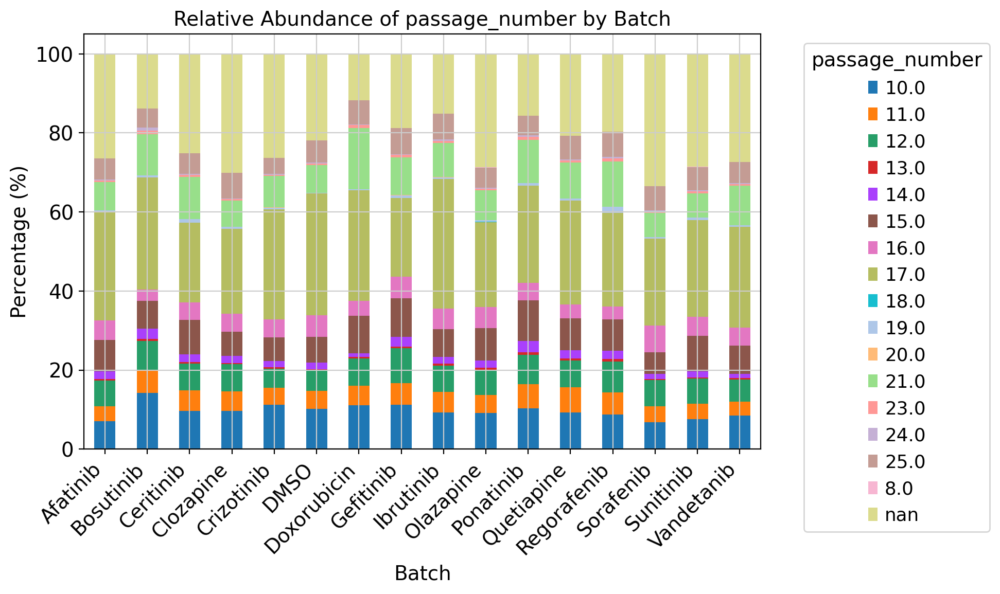

In [34]:
plot_composition_bar(
    adata=adata,
    x_key='Batch', 
    stack_key='passage_number',
    x_mapping=sample_exposure
)

In [43]:
import os
import pandas as pd
import anndata
from typing import Optional, Dict

In [11]:

from matplotlib.patches import Patch
def plot_split_composition_bar(
    adata: anndata.AnnData, 
    x_key: str, 
    split_key: str,
    stack_key: str, 
    x_mapping: Optional[Dict[str, str]] = None,
    split_mapping: Optional[Dict[str, str]] = None,
    stack_mapping: Optional[Dict[str, str]] = None,
    figsize: Tuple[int, int] = (14, 6),
    save_path: Optional[str] = None,
    show: bool = True
):
    # --- NEW: Call external function to generate and save the CSV data table ---
    _ = generate_proportion_df(
        adata=adata, x_key=x_key, stack_key=stack_key, split_key=split_key,
        x_mapping=x_mapping, stack_mapping=stack_mapping, split_mapping=split_mapping, 
        save_path=save_path
    )
    
    # (Rest of the plotting logic with hatches and dual legend adjustment)
    for key in [x_key, split_key, stack_key]:
        if key not in adata.obs.columns: raise ValueError(f"'{key}' not found")
    df = adata.obs[[x_key, split_key, stack_key]].copy()
    color_key = f'{stack_key}_colors'
    has_scanpy_colors = color_key in adata.uns
    custom_order = None
    if has_scanpy_colors and hasattr(adata.obs[stack_key], 'cat'):
        orig_categories = list(adata.obs[stack_key].cat.categories.astype(str))
        custom_order = [stack_mapping.get(cat, cat) for cat in orig_categories] if stack_mapping else orig_categories
    mappings = {x_key: x_mapping, split_key: split_mapping, stack_key: stack_mapping}
    for k, m in mappings.items():
        df[k] = df[k].astype(str).replace(m) if m else df[k].astype(str)
    count_table = pd.crosstab(index=[df[x_key], df[split_key]], columns=df[stack_key])
    proportion_table = count_table.div(count_table.sum(axis=1), axis=0) * 100
    stack_categories = list(proportion_table.columns)
    if custom_order:
        stack_categories = [c for c in custom_order if c in stack_categories]
        proportion_table = proportion_table[stack_categories]
    x_categories, split_categories = sorted(df[x_key].unique()), sorted(df[split_key].unique())
    n_x, n_split = len(x_categories), len(split_categories)
    x_indices = np.arange(n_x)
    bar_width = 0.8 / n_split
    if has_scanpy_colors: color_map = dict(zip(stack_categories, adata.uns[color_key]))
    else:
        import matplotlib.cm as cm
        cmap = cm.get_cmap('tab20', len(stack_categories))
        color_map = {cat: cmap(i) for i, cat in enumerate(stack_categories)}
    hatch_patterns = ['', '//', '..', 'xx']
    fig, ax = plt.subplots(figsize=figsize, dpi=100)
    for s_idx, s_val in enumerate(split_categories):
        offset = (s_idx - (n_split - 1) / 2) * bar_width
        pos = x_indices + offset
        hatch = hatch_patterns[s_idx % len(hatch_patterns)]
        sub_df = proportion_table.xs(s_val, level=split_key).reindex(x_categories).fillna(0) if s_val in proportion_table.index.get_level_values(1) else pd.DataFrame(0, index=x_categories, columns=stack_categories)
        bottom = np.zeros(n_x)
        for stack_val in stack_categories:
            ax.bar(pos, sub_df[stack_val].values, bottom=bottom, width=bar_width, color=color_map[stack_val], label=stack_val if s_idx == 0 else None, edgecolor='black', linewidth=0.6, hatch=hatch)
            bottom += sub_df[stack_val].values
    ax.set_xticks(x_indices)
    ax.set_xticklabels(x_categories, rotation=45, ha='right', fontsize=10)
    ax.set_ylabel('Percentage (%)')
    ax.set_title(f'Abundance of {stack_key} by {x_key} (Stratified by {split_key})', weight='bold', pad=15)
    ax.set_ylim(0, 100)
    legend1 = ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title=stack_key)
    ax.add_artist(legend1)
    split_handles = [Patch(facecolor='lightgrey', edgecolor='black', hatch=hatch_patterns[i % len(hatch_patterns)], label=s_val) for i, s_val in enumerate(split_categories)]
    legend2 = ax.legend(handles=split_handles, bbox_to_anchor=(1.02, 0.4), loc='upper left', title=split_key)
    plt.tight_layout()
    fig.subplots_adjust(right=0.82)
    if save_path is not None:
        plt.savefig(save_path, bbox_inches='tight', bbox_extra_artists=(legend1, legend2), dpi=300)
        print(f"Figure saved successfully to: {save_path}")
    if show: plt.show()
    else: plt.close(fig)

Dataframe saved successfully to: /g/data/wy83/cardiotoxicity/analysis/anndata/test_data_analysis/dim_reduction/exposure_vs_celltype_vs_sex_proportions.csv
Figure saved successfully to: /g/data/wy83/cardiotoxicity/analysis/anndata/test_data_analysis/dim_reduction/exposure_vs_celltype_vs_sex_proportions.png


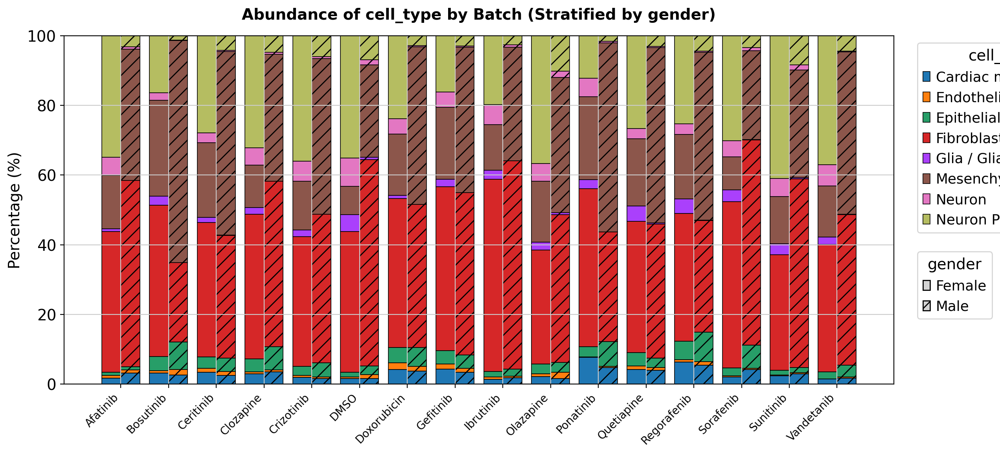

In [47]:
plot_split_composition_bar(
    adata=adata,
    x_key='Batch',                # Main grouping on X-axis (Samples)
    split_key='gender',           # Variable that splits each group into side-by-side bars
    stack_key='cell_type',           # Variable determining the internal stack colors (Clusters)
    x_mapping=sample_exposure,    # Re-maps Sample-1 to "DMSO", etc.
#    split_mapping=gender_clean,   # Re-maps "M"/"F" to "Male"/"Female"
#    stack_mapping=leiden_res0_15_celltypes, # Re-maps cluster numbers to cell types
#    save_path='plots/stratified_cell_abundance.png',
#    figsize=(14, 7),
    save_path="/g/data/wy83/cardiotoxicity/analysis/anndata/test_data_analysis/dim_reduction/exposure_vs_celltype_vs_sex_proportions.png"
)

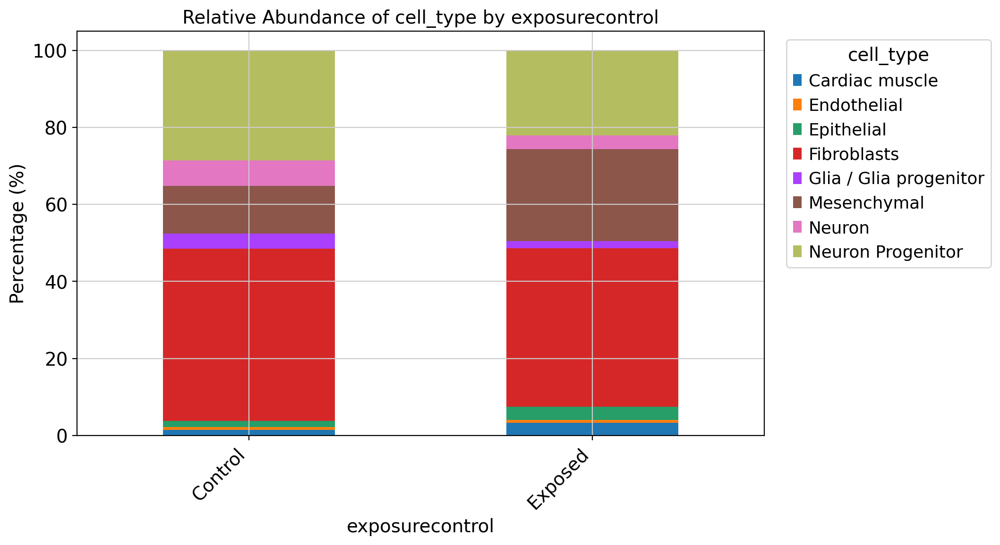

In [52]:
adata.obs['exposurecontrol'] = np.where(
    adata.obs['Batch'] == 'Sample-1_anndata', 
    'Control', 
    'Exposed'
)
plot_composition_bar(
    adata=adata,
    x_key='exposurecontrol', 
    stack_key='cell_type',
    x_mapping=sample_exposure
)

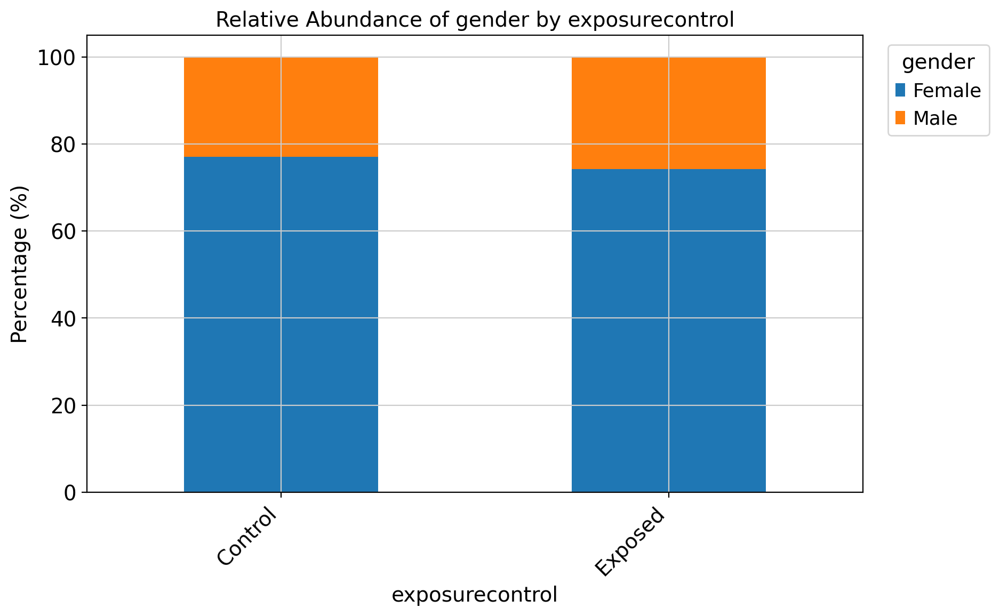

In [54]:
plot_composition_bar(
    adata=adata,
    x_key='exposurecontrol', 
    stack_key='gender',
    x_mapping=sample_exposure
)

In [51]:
save_path = "/g/data/wy83/cardiotoxicity/analysis/anndata/full_data_analysis/dim_reduction/results/test"
#resolution=f"leiden_res{res_string}"
#resolution_df = adata.obs[[resolution]]
cell_type_df = adata.obs['cell_type']
csv_file = os.path.join(save_path, f"cell_type_assignments_mini_full_adata.csv")
cell_type_df.to_csv(csv_file)
cell_type_df

QSR-5+32+07+20+4A           Mesenchymal
QSR-8+66+50+55+5A           Fibroblasts
QSR-8+44+76+33+5D           Fibroblasts
QSR-4+93+61+03+1G     Neuron Progenitor
QSR-6+86+37+32+2B     Neuron Progenitor
                            ...        
QSR-8+81+37+81+6A           Fibroblasts
QSR-1+75+77+72+6F        Cardiac muscle
QSR-1+17+90+77+9E           Mesenchymal
QSR-6+77+80+32+10C           Epithelial
QSR-2+81+85+16+2D           Fibroblasts
Name: cell_type, Length: 99227, dtype: category
Categories (8, object): ['Cardiac muscle', 'Endothelial', 'Epithelial', 'Fibroblasts', 'Glia / Glia progenitor', 'Mesenchymal', 'Neuron', 'Neuron Progenitor']

### Cell type proportion changes

For this step I use scCODA, which inspired by compositional ananlysis of microbiome data, uses a Bayesian approach to adress low replicates. Furthermore it models cill-type counts using hierarchical Dirichlet-Multinomial model. It uses a specidic cell type as reference, and tchanges in composition of a cell type are seen in relation to the selected reference.
What would be a a good reference cell type? -> common cell type  (could be most aboundant, ideally one that we expect to be stable) 


In [12]:
import warnings

import decoupler as dc
import pertpy as pt
import scanpy as sc

In [13]:
#1. Initialize the scCODA tool
sccoda = pt.tl.Sccoda()

In [ ]:
haber_cells = pt.dt.haber_2017_regions()
haber_cells.obs

! Download attempt 1/3 failed: HTTPSConnectionPool(host='scverse-exampledata.s3.eu-west-1.amazonaws.com', port=443): Max retries exceeded with url: /pertpy/haber_2017_regions.h5ad (Caused by NewConnectionError("HTTPSConnection(host='scverse-exampledata.s3.eu-west-1.amazonaws.com', port=443): Failed to establish a new connection: [Errno 101] Network is unreachable")). Retrying in 5 seconds...
! Download attempt 2/3 failed: HTTPSConnectionPool(host='scverse-exampledata.s3.eu-west-1.amazonaws.com', port=443): Max retries exceeded with url: /pertpy/haber_2017_regions.h5ad (Caused by NewConnectionError("HTTPSConnection(host='scverse-exampledata.s3.eu-west-1.amazonaws.com', port=443): Failed to establish a new connection: [Errno 101] Network is unreachable")). Retrying in 5 seconds...
! Download attempt 3/3 failed: HTTPSConnectionPool(host='scverse-exampledata.s3.eu-west-1.amazonaws.com', port=443): Max retries exceeded with url: /pertpy/haber_2017_regions.h5ad (Caused by NewConnectionError(


KeyboardInterrupt



### composition plots

In [50]:
adata

AnnData object with n_obs × n_vars = 135240 × 23845
    obs: 'cell_id', 'counts', 'genes', 'totalReads', 'countedReads', 'mappedReads', 'geneReads', 'exonReads', 'intronReads', 'antisenseReads', 'mitoReads', 'countedMultiGeneReads', 'Saturation', 'mitoProp', 'PCR', 'RT', 'bead_bc', 'sample', 'flags', 'sample_id', 'Batch', 'Donor_ID', 'growth_rate', 'passage_number', 'village_id', 'village_id_2', 'maxi_village_id', 'maxi_village_id_2', 'collection_age', 'gender', 'ethnicity', 'disease_status', 'stem_cell_project', 'PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'Batch name', 'ct_cardiovascular_disease', 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'S_score', 'G2M_score', 'phase', 'leiden_r0.1', 'leiden_r0.15', 'leiden_r0.18', 'leiden_r0.2', 'leiden_res0_2'
    var: 'n_cells', 'n_counts', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_drop

In [51]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
import scanpy as sc
import anndata
from typing import Optional, Tuple, Dict

def plot_donor_composition(
    adata: anndata.AnnData,
    donor_key: str,
    stack_key: str,
    batch_key: str = 'Batch_meta',
    batch_filter: Optional[str] = None,
    gender_key: str = 'gender',
    village1_key: str = 'village_id',
    village2_key: str = 'village_id_2',
    stack_mapping: Optional[Dict[str, str]] = None,
    figsize: Tuple[int, int] = (45, 10),
    save_path: Optional[str] = None,
    show: bool = True
):
    """
    Plots cell type compositions for donors sorted by abundance.
    Appends the abundance rank to the donor ID on the x-axis label.
    """
    # 1. Filter data by batch if requested
    df_full = adata.obs.copy()
    if batch_filter is not None:
        if batch_filter not in df_full[batch_key].astype(str).values:
            raise ValueError(f"Batch '{batch_filter}' not found in column '{batch_key}'")
        df = df_full[df_full[batch_key].astype(str) == batch_filter].copy()
    else:
        df = df_full
        
    total_cells = len(df)
    if total_cells == 0:
        raise ValueError("No cells found for the given criteria.")

    # 2. Map the stack keys to final cell type strings up front
    if stack_mapping:
        df[stack_key] = df[stack_key].astype(str).map(stack_mapping).fillna(df[stack_key].astype(str))
    else:
        df[stack_key] = df[stack_key].astype(str)

    # 3. Sort unique cell types alphabetically
    stack_categories = sorted(df[stack_key].unique())
    n_cats = len(stack_categories)

    # 4. Calculate donor sorting order (Descending representation)
    donor_counts = df[donor_key].value_counts()
    donor_proportions = donor_counts / total_cells
    sorted_donors = list(donor_counts.index)

    # 5. Generate composition tables aligned to sorted donors
    count_table = pd.crosstab(df[donor_key], df[stack_key]).reindex(index=sorted_donors, columns=stack_categories).fillna(0)
    proportion_table = count_table.div(count_table.sum(axis=1), axis=0) * 100

    # 6. Extract/Generate Colors to EXACTLY match sc.pl.umap()
    color_key = f'{stack_key}_colors'
    if color_key in adata.uns and len(adata.uns[color_key]) == n_cats:
        colors = list(adata.uns[color_key])
    else:
        if n_cats <= 10:
            palette = sc.pl.palettes.default_10
        elif n_cats <= 20:
            palette = sc.pl.palettes.default_20
        elif n_cats <= 28:
            palette = sc.pl.palettes.default_28
        else:
            palette = sc.pl.palettes.default_102
        colors = palette[:n_cats]
        
    color_map = dict(zip(stack_categories, colors))

    # 7. Extract metadata tracking arrays mapped precisely to sorted donors
    donor_metadata = df.drop_duplicates(subset=[donor_key]).set_index(donor_key).reindex(sorted_donors)
    
    # 8. Build the 0.01 inflected custom colormap for the proportion block
    max_prop = donor_proportions.max()
    min_prop = donor_proportions.min()
    vcenter = 0.01
    vmin = min(0.0, min_prop)
    vmax = max(vcenter + 0.01, max_prop)
    
    norm = mcolors.TwoSlopeNorm(vcenter=vcenter, vmin=vmin, vmax=vmax)
    prop_cmap = mcolors.LinearSegmentedColormap.from_list(
        'prop_divergent', ['#8b0000', '#ffcccc', '#ffffff', '#e5f5e0', '#006d2c']
    )

    # 9. Initialize Plot Coordinates
    fig, ax = plt.subplots(figsize=figsize, dpi=100)
    x_indices = np.arange(len(sorted_donors))
    bar_width = 0.75
    
    # Plot standard 100% stacked compositions
    bottom = np.zeros(len(sorted_donors))
    for stack_val in stack_categories:
        pct_vals = proportion_table[stack_val].values
        ax.bar(x_indices, pct_vals, bottom=bottom, width=bar_width,
               color=color_map[stack_val], label=stack_val, edgecolor='black', linewidth=0.5)
        bottom += pct_vals

    # 10. Define Tracking Heights
    y_gender_start = 103
    y_gender_height = 3.5
    
    y_prop_start = 108.5
    y_prop_height = 14
    
    y_count_start = 124.5
    y_count_height = 14
    
    y_village_start = 140.5
    y_village_height = 3.5

    # Left-aligned row labels
    label_x_pos = -0.7
    ax.text(label_x_pos, y_gender_start + (y_gender_height / 2), "Sex", 
            ha='right', va='center', fontsize=10, weight='bold', color='black')
    ax.text(label_x_pos, y_prop_start + (y_prop_height / 2), "Proportion", 
            ha='right', va='center', fontsize=10, weight='bold', color='black')
    ax.text(label_x_pos, y_count_start + (y_count_height / 2), "Cell Count", 
            ha='right', va='center', fontsize=10, weight='bold', color='black')
    ax.text(label_x_pos, y_village_start + (y_village_height / 2), "Village Status", 
            ha='right', va='center', fontsize=10, weight='bold', color='black')

    # 11. Render Metadata Track Boxes
    for idx, donor in enumerate(sorted_donors):
        # Track 1: Sex/Gender (Small Box)
        gender = str(donor_metadata.loc[donor, gender_key]).lower()
        if 'female' in gender or gender == 'f':
            gender_color = '#8928f7'
        elif 'male' in gender or gender == 'm':
            gender_color = '#dea918'
        else:
            gender_color = '#d3d3d3'
        ax.bar(x_indices[idx], y_gender_height, bottom=y_gender_start, width=bar_width, 
               color=gender_color, edgecolor='black', linewidth=0.5)

        # Track 2: Proportion Gradient
        p_val = donor_proportions.loc[donor]
        grad_color = prop_cmap(norm(p_val))
        ax.bar(x_indices[idx], y_prop_height, bottom=y_prop_start, width=bar_width, 
               color=grad_color, edgecolor='black', linewidth=0.5)
        ax.text(x_indices[idx], y_prop_start + (y_prop_height / 2), f"{p_val:.4f}", 
                ha='center', va='center', rotation=90, fontsize=8, weight='bold', color='black')

        # Track 3: Absolute Cell Count
        c_val = donor_counts.loc[donor]
        ax.bar(x_indices[idx], y_count_height, bottom=y_count_start, width=bar_width, 
               color='#f7f7f7', edgecolor='black', linewidth=0.5)
        ax.text(x_indices[idx], y_count_start + (y_count_height / 2), f"{int(c_val)}", 
                ha='center', va='center', rotation=90, fontsize=8, weight='bold', color='black')

        # Track 4: Village Status Binary Flag (Small Box)
        v1 = donor_metadata.loc[donor, village1_key]
        v2 = donor_metadata.loc[donor, village2_key]
        
        has_v1 = pd.notna(v1) and str(v1).strip() != '' and str(v1).lower() != 'nan'
        has_v2 = pd.notna(v2) and str(v2).strip() != '' and str(v2).lower() != 'nan'
        
        if has_v1 and not has_v2:
            village_color = '#4682b4'
        elif has_v1 and has_v2:
            village_color = '#20b2aa'
        else:
            village_color = '#e0e0e0'
            
        ax.bar(x_indices[idx], y_village_height, bottom=y_village_start, width=bar_width, 
               color=village_color, edgecolor='black', linewidth=0.5)

    # 12. Graph Formatting & NEW: Ranked X-axis Labels
    ax.set_xlim(-1.8, len(sorted_donors) - 0.4)
    ax.set_ylim(0, 146)
    ax.set_xticks(x_indices)
    
    # Generate labels dynamically formatted as "Rank- Donor_ID"
    ranked_labels = [f"{i + 1}- {donor}" for i, donor in enumerate(sorted_donors)]
    ax.set_xticklabels(ranked_labels, rotation=45, ha='right', fontsize=9)
    
    ax.set_ylabel('Percentage Composition / Meta Indicators', fontsize=11, weight='bold')
    
    title_suffix = f" (Filtered by Batch: {batch_filter})" if batch_filter else " (All Batches)"
    ax.set_title(f"Donor Abundance Matrix Profiles{title_suffix}", weight='bold', pad=20, fontsize=13)

    # 13. Legends Alignment
    cell_handles, cell_labels = ax.get_legend_handles_labels()
    legend_cells = ax.legend(cell_handles, cell_labels, bbox_to_anchor=(1.02, 1.0), loc='upper left', title=stack_key)
    ax.add_artist(legend_cells)

    meta_elements = [
        Patch(facecolor='#dea918', edgecolor='black', label='Male'),
        Patch(facecolor='#8928f7', edgecolor='black', label='Female'),
        Patch(facecolor='#4682b4', edgecolor='black', label='Village ID Only'),
        Patch(facecolor='#20b2aa', edgecolor='black', label='Both Village IDs')
    ]
    legend_meta = ax.legend(handles=meta_elements, bbox_to_anchor=(1.02, 0.45), loc='upper left', title="Track Legends")

    plt.tight_layout()
    fig.subplots_adjust(right=0.80)

    # 14. Save & Show Control
    if save_path is not None:
        directory = os.path.dirname(save_path)
        if directory and not os.path.exists(directory):
            os.makedirs(directory)
        plt.savefig(save_path, bbox_inches='tight', bbox_extra_artists=(legend_cells, legend_meta), dpi=300)
        print(f"Manifest plot saved successfully to: {save_path}")
        
    if show: 
        plt.show()
    else: 
        plt.close(fig)

In [41]:
sample_exposure = {
    "Sample-1_anndata" : "DMSO",
    "Sample-2_anndata" : "Afatinib",
    "Sample-3_anndata" : "Bosutinib",
    "Sample-4_anndata" : "Ceritinib",
    "Sample-5_anndata" : "Clozapine",
    "Sample-6_anndata" : "Crizotinib",
    "Sample-7_anndata" : "Doxorubicin",
    "Sample-8_anndata" : "Gefitinib",
    "Sample-9_anndata" : "Ibrutinib",
    "Sample-10_anndata" : "Olazapine",
    "Sample-11_anndata" : "Ponatinib",
    "Sample-12_anndata" : "Quetiapine",
    "Sample-13_anndata" : "Regorafenib",
    "Sample-14_anndata" : "Sorafenib",
    "Sample-15_anndata" : "Sunitinib",
    "Sample-16_anndata" : "Vandetanib"
}
adata.obs['exposure'] = adata.obs['Batch'].map(sample_exposure)

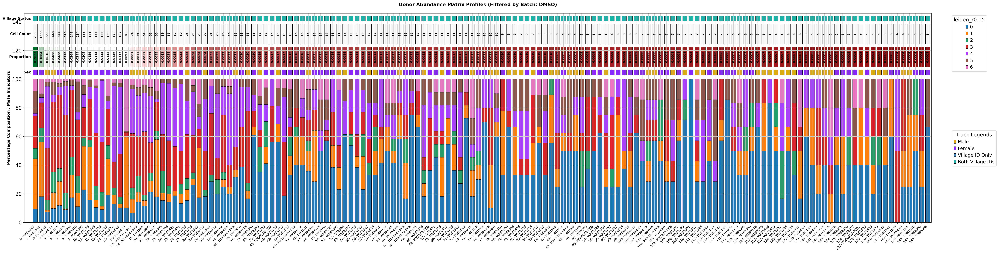

In [55]:
plot_donor_composition(
    adata=adata,
    donor_key='Donor_ID',
    stack_key='leiden_r0.15',
    batch_key='exposure',
    batch_filter='DMSO',          # Only counts/proportions within Batch_3 are evaluated
    #stack_mapping=leiden_celltypes,
    #save_path='plots/batch3_donor_manifest.png'
)

### Cell 